### Run this notebook online

[![Open in Colab](https://img.shields.io/badge/Open_in-Colab-F9AB00?logo=googlecolab&logoColor=F9AB00)](https://colab.research.google.com/github/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/CIFAR10%20DiT%20CLF.ipynb)
[![Open in Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://www.kaggle.com/kernels/welcome?src=https%3A%2F%2Fgithub.com%2Fhosein-fanai%2FContinual-Learning-with-Diffusion-Vision-Transformers%2Fblob%2Fmain%2Ffiles%2Fnotebooks%2FCIFAR10%2520DiT%2520CLF.ipynb)
[![Launch Binder](https://img.shields.io/badge/launch-binder-F5793A?logo=jupyter&logoColor=white)](https://mybinder.org/v2/gh/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/main?urlpath=lab%2Ftree%2Ffiles%2Fnotebooks%2FCIFAR10%20DiT%20CLF.ipynb)

- **Google Colab:** open the notebook, select a GPU for training under **Runtime > Change runtime type**, then choose **Run all**.
- **Kaggle:** sign in and import the notebook, enable **Internet**, select a **GPU** accelerator for training, then **Run all**.
- **Binder:** opens a temporary CPU JupyterLab session. Use it to inspect the notebook or run small checks; full training needs more resources.
- **[Studio Lab](https://studiolab.sagemaker.aws/import/github/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/CIFAR10%20DiT%20CLF.ipynb) (existing accounts only):** start a runtime, copy the notebook to your project, select a Python **3.11–3.13** kernel, and set `RUNTIME = "studiolab"` in the first code cell before **Run all**. For CPU, also set `CUDA = False`.

The **first code cell** finds or downloads the repository and prepares TensorFlow **2.20** / Keras **3.11.2** before project imports. If setup requests a restart, restart the kernel and run all again. For another hosted Jupyter service, set `RUNTIME = "hosted"` (`CUDA = False` for CPU or compatible provider-managed CUDA). Locally, select the project TensorFlow kernel.

Launch links open the published GitHub `main` version; publish this notebook and its setup files together before using them. For a notebook that has not been published, upload its `.ipynb` file to Colab or Kaggle instead. GPU availability depends on the provider. Save checkpoints and results before a temporary session ends.

See the [hosted runtime guide](https://github.com/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/thesis/README.md#hosted-runtimes) for setup and import details.


In [1]:
"""Prepare a notebook checkout and runtime before importing scientific packages.

This canonical first-cell source is copied into maintained notebooks and generated
HPO notebooks. Edit REVISION/RUNTIME/CUDA before execution when needed. Existing
checkouts are reused without fetching; only missing setup code is downloaded.
ROOT is the selected absolute pathlib.Path; RUNTIME_PACKAGES maps package names
to installed version strings. Preparation may clone/install under the selected
policy and changes cwd/import paths through files.notebooks.init.prepare_notebook.
"""
from pathlib import Path
from urllib.request import urlopen


CHECKOUT_NAME = "Continual-Learning-with-Diffusion-Vision-Transformers"
REPOSITORY = f"https://github.com/hosein-fanai/{CHECKOUT_NAME}.git"
REVISION = "main"
RUNTIME = "auto"  # Use "hosted" for another online service, or "local" to verify only.
CUDA = None  # False: CPU or managed CUDA; True: retain CUDA pip dependencies.

_locations = (Path.cwd(), *Path.cwd().parents, Path.cwd() / CHECKOUT_NAME, 
              Path("/kaggle/working") / CHECKOUT_NAME, Path("/content") / CHECKOUT_NAME)
_initializer = next((path / "files" / "notebooks" / "init.py" for path in _locations
                     if (path / "files" / "notebooks" / "init.py").is_file()), None)
_url = f"https://raw.githubusercontent.com/hosein-fanai/{CHECKOUT_NAME}/{REVISION}/files/notebooks/init.py"
_setup = {"__name__": "notebook_setup", "__file__": str(_initializer or _url)}
with (_initializer.open("rb") if _initializer else urlopen(_url, timeout=30)) as _file:
    exec(compile(_file.read(), _setup["__file__"], "exec"), _setup)
ROOT, RUNTIME_PACKAGES = _setup["prepare_notebook"](
    checkout_name=CHECKOUT_NAME, 
    repository=REPOSITORY, 
    revision=REVISION, 
    runtime=RUNTIME, 
    cuda=CUDA
)


Repository ready: /workspace/Continual-Learning-with-Diffusion-Vision-Transformers (runtime: local)
Runtime packages ready: Python 3.12.3, TensorFlow 2.20.0, Keras 3.11.2


In [2]:
from common import utils


utils.init()

2026-10-12 19:43:01.357314: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Experiment settings


In [3]:
epochs = 100

## CIFAR10 data


In [4]:
from common.dataloader import load_cifar10, get_dataset


x_train, y_train, _, _, x_test, y_test = load_cifar10(
    indices=None, 
    validation_ratio=0.0, 
    verbose=0
)

trainset = get_dataset(x_train, y_train.reshape(-1))
valset = get_dataset(x_test, y_test.reshape(-1), shuffle_buffer=0, drop_remainder=False)

2026-10-12 19:43:10.675603: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1791834190.676901  130199 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 74659 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:87:00.0, compute capability: 8.0


## DiT denoiser and classifier


In [5]:
from diffusion.models.transformer.di_t_classifier import DiTClassifier
from diffusion.models.wrapper.diffusion_classifier import DiffusionClassifier


vit = DiTClassifier(
    image_size=32, 
    channels=3, 
    patchify_with_cnn=True, 
    depth=8, 
    dim=128, 
    clf_depth=8, 
    clf_droppath_rate=0.05, 
    classifier_dropout_rate=0.5, 
    force_global_avg_pooling=True
)
model = DiffusionClassifier(
    network=vit, 
    use_ema=False, 
    modify_first_t=True, 
    clf_loss_coef=0.00215, 
    clf_acc_coef=1., 
    clf_distil_acc_coef=0., 
    clf_train_class_input_type="null_class_only", 
    clf_train_noisified_max_timesteps=64, 
    clf_test_noisified_max_timesteps=0, 
    train_noisified_max_timesteps=1000, 
    mask_by_nulls=False, 
    test_steps=100, 
    test_cfg_scale=3.0
)

vit.summary()

Model: "di_t_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ depth_0_patch_embedder          │ (None, 256, 128)       │        75,648 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_embedder           │ (None, 128)            │       128,000 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_label_embedder          │ (None, 128)            │         1,408 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_label_merger (Add) │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_1_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_2_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_3_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_4_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_5_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_6_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_7_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_8_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ unpatchifier (Functional)       │ (None, 32, 32, 3)      │        34,572 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_0_cls_token           │ (None, 1, 128)         │           256 │
│ (SingleTokenLayer)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_1_feature_aggregator  │ (None, 256, 128)       │             0 │
│ (FeatureHandler)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_1_encoder_block       │ (None, 257, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_2_encoder_block       │ (None, 257, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 4,990,582 (19.04 MB)

 Trainable params: 4,862,486 (18.55 MB)

 Non-trainable params: 128,096 (500.75 KB)

## Optimizer


In [6]:
from tensorflow.keras import optimizers


lr_schedule = optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-3, 
    decay_steps=epochs * len(trainset)
)

model.compile(
    optimizer=optimizers.Adam(lr_schedule), 
    loss="mse"
)

In [7]:
from tensorflow.keras import callbacks

from common.callbacks.lr_logger import LrLogger

from diffusion.callbacks.image_generator import ImageGenerator


callbacks_list = [
    LrLogger(), 
    callbacks.ProgbarLogger(), 
    ImageGenerator()
]

## Training


Epoch 1/100


2026-10-12 19:43:48.901735: I external/local_xla/xla/service/service.cc:163] XLA service 0x7b2ff4001a30 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-12 19:43:48.901770: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA A100-SXM4-80GB, Compute Capability 8.0
2026-10-12 19:43:50.242891: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-12 19:43:55.989726: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002
2026-10-12 19:44:01.920227: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-12 19:44:01.920866: I ext

390/390 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - classifier_accuracy: 0.1959 - classifier_loss: 2.1910 - loss: 0.1987 - noise_loss: 0.1940

2026-10-12 19:48:13.017335: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-12 19:48:19.956511: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_70', 304 bytes spill stores, 304 bytes spill loads

2026-10-12 19:48:20.585016: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 4 bytes spill stores, 4 bytes spill loads

2026-10-12 19:48:24.767789: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6', 276 bytes spill

390/390 ━━━━━━━━━━━━━━━━━━━━ 405s 418ms/step - classifier_accuracy: 0.2536 - classifier_loss: 2.0141 - loss: 0.0839 - noise_loss: 0.0796 - val_classifier_accuracy: 0.3875 - val_classifier_loss: 1.6335 - val_image_loss: 0.1689 - val_loss: 0.0397 - val_noise_loss: 0.0362 - learning_rate: 9.9975e-04
Steps: 100/100


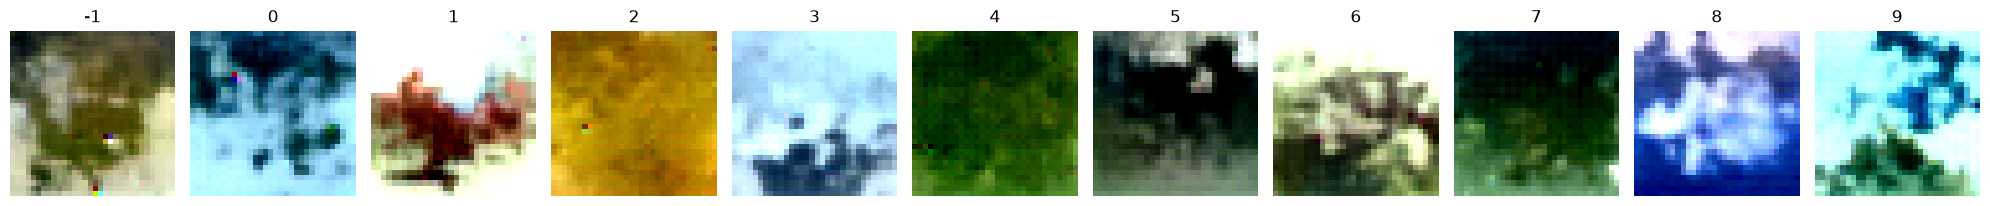

Epoch 2/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 57s 146ms/step - classifier_accuracy: 0.4212 - classifier_loss: 1.5732 - loss: 0.0387 - noise_loss: 0.0353 - val_classifier_accuracy: 0.5084 - val_classifier_loss: 1.3396 - val_image_loss: 0.1169 - val_loss: 0.0372 - val_noise_loss: 0.0343 - learning_rate: 9.9901e-04
Steps: 100/100


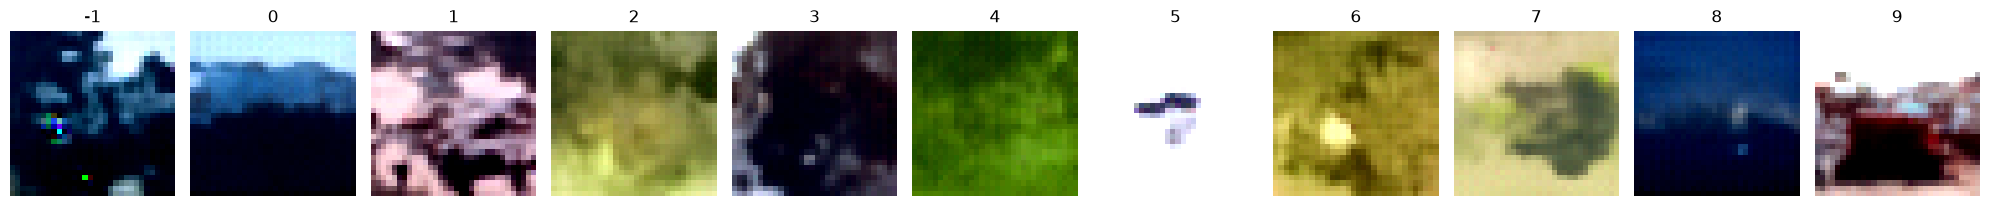

Epoch 3/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 57s 146ms/step - classifier_accuracy: 0.4976 - classifier_loss: 1.3886 - loss: 0.0363 - noise_loss: 0.0333 - val_classifier_accuracy: 0.5630 - val_classifier_loss: 1.2195 - val_image_loss: 0.1145 - val_loss: 0.0375 - val_noise_loss: 0.0349 - learning_rate: 9.9778e-04
Steps: 100/100


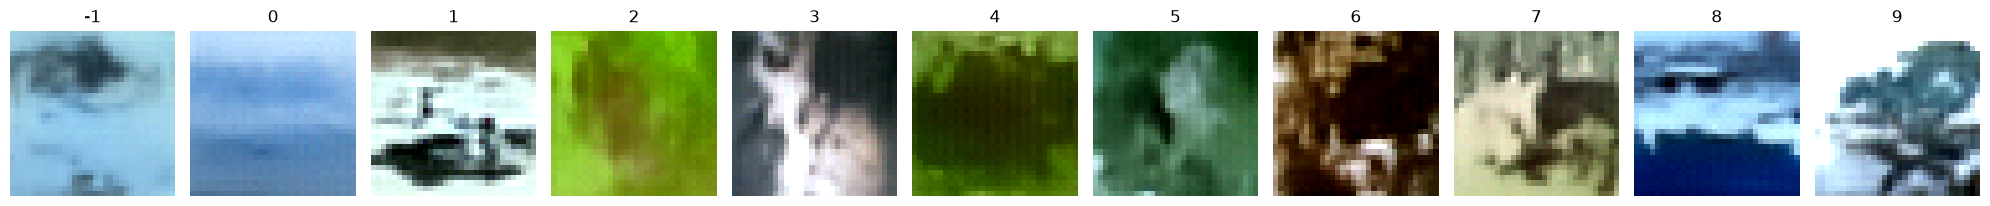

Epoch 4/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 58s 147ms/step - classifier_accuracy: 0.5462 - classifier_loss: 1.2601 - loss: 0.0354 - noise_loss: 0.0327 - val_classifier_accuracy: 0.6234 - val_classifier_loss: 1.0558 - val_image_loss: 0.1122 - val_loss: 0.0361 - val_noise_loss: 0.0338 - learning_rate: 9.9606e-04
Steps: 100/100


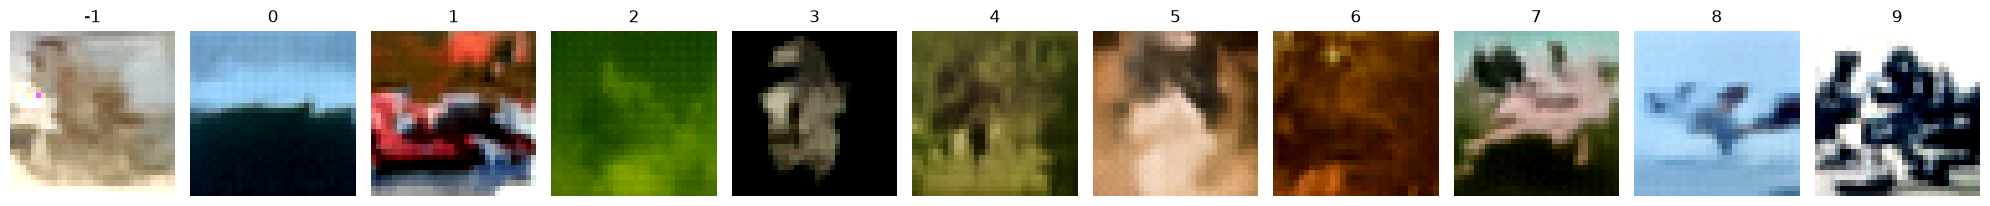

Epoch 5/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 58s 148ms/step - classifier_accuracy: 0.5817 - classifier_loss: 1.1718 - loss: 0.0350 - noise_loss: 0.0325 - val_classifier_accuracy: 0.6329 - val_classifier_loss: 0.9997 - val_image_loss: 0.0969 - val_loss: 0.0354 - val_noise_loss: 0.0332 - learning_rate: 9.9384e-04
Steps: 100/100


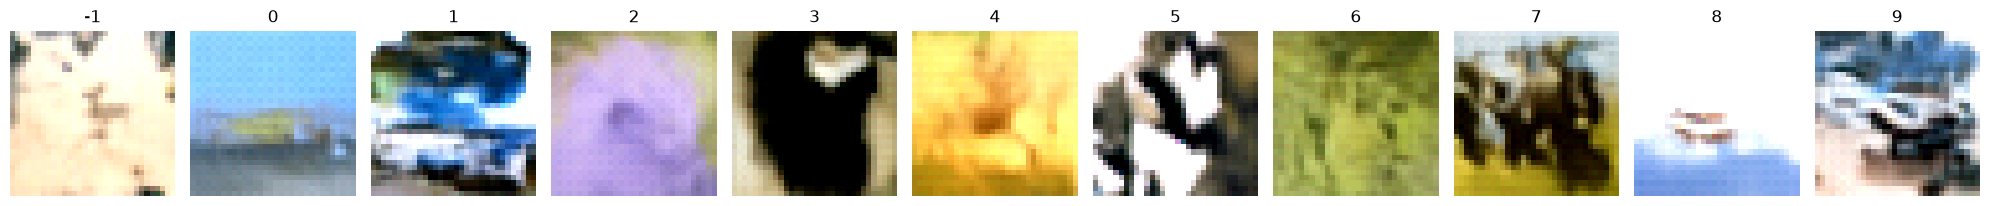

Epoch 6/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 57s 146ms/step - classifier_accuracy: 0.6095 - classifier_loss: 1.1019 - loss: 0.0341 - noise_loss: 0.0318 - val_classifier_accuracy: 0.6359 - val_classifier_loss: 1.0242 - val_image_loss: 0.0975 - val_loss: 0.0356 - val_noise_loss: 0.0334 - learning_rate: 9.9114e-04
Steps: 100/100


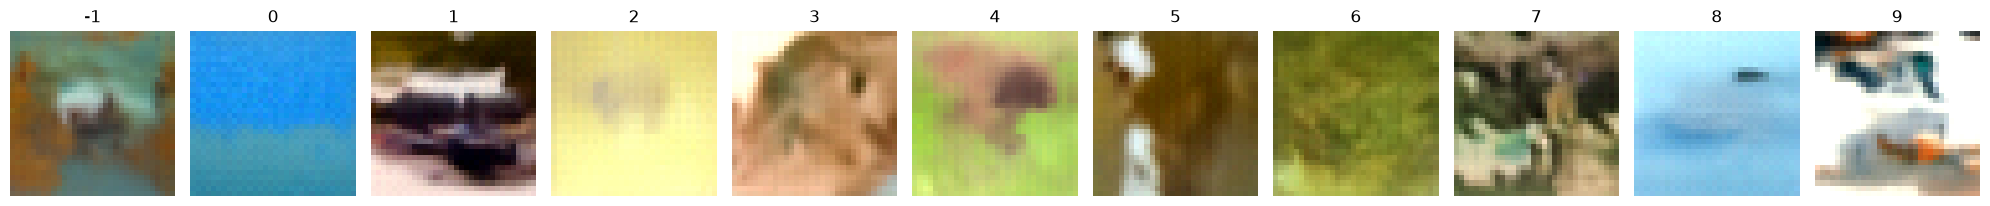

Epoch 7/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 53s 136ms/step - classifier_accuracy: 0.6277 - classifier_loss: 1.0441 - loss: 0.0340 - noise_loss: 0.0317 - val_classifier_accuracy: 0.6499 - val_classifier_loss: 0.9671 - val_image_loss: 0.0916 - val_loss: 0.0358 - val_noise_loss: 0.0337 - learning_rate: 9.8796e-04
Steps: 100/100


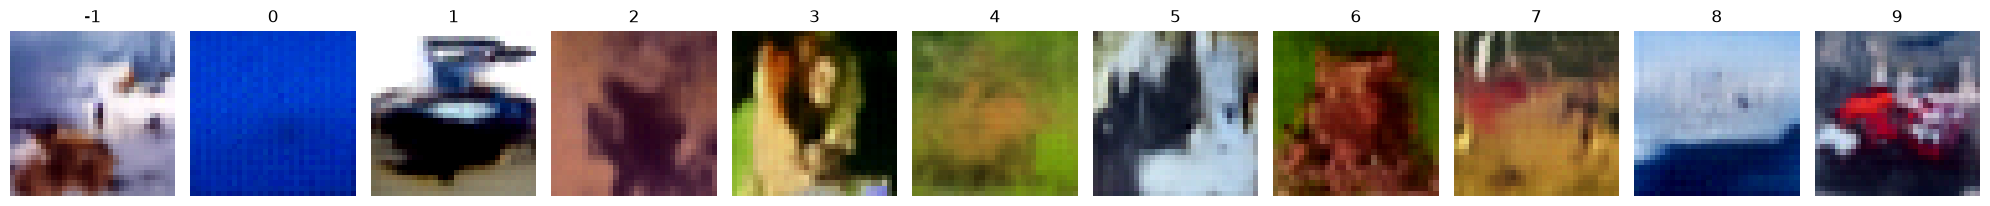

Epoch 8/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 56s 142ms/step - classifier_accuracy: 0.6495 - classifier_loss: 0.9947 - loss: 0.0339 - noise_loss: 0.0318 - val_classifier_accuracy: 0.6743 - val_classifier_loss: 0.9260 - val_image_loss: 0.0923 - val_loss: 0.0348 - val_noise_loss: 0.0328 - learning_rate: 9.8429e-04
Steps: 100/100


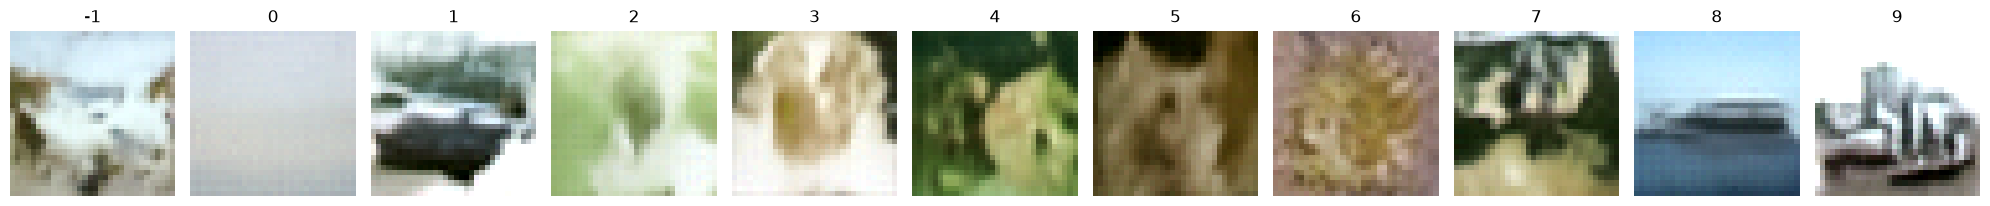

Epoch 9/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.6626 - classifier_loss: 0.9578 - loss: 0.0336 - noise_loss: 0.0315 - val_classifier_accuracy: 0.6830 - val_classifier_loss: 0.8780 - val_image_loss: 0.0887 - val_loss: 0.0346 - val_noise_loss: 0.0327 - learning_rate: 9.8015e-04
Steps: 100/100


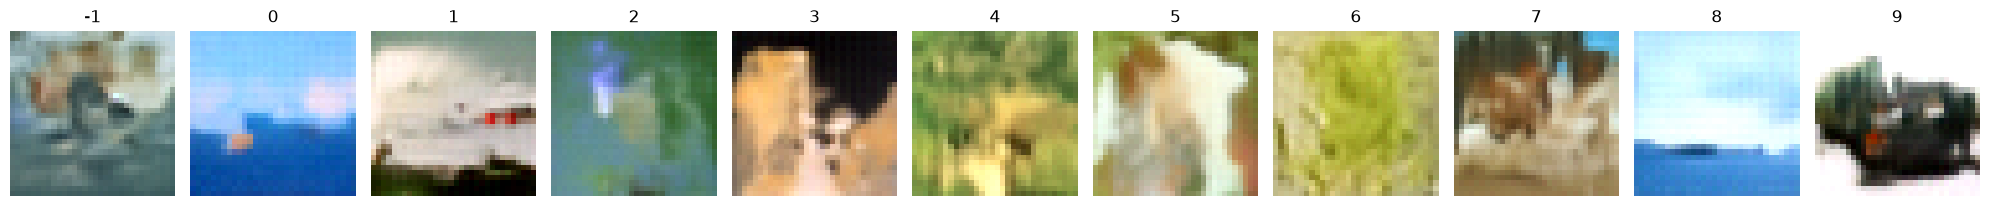

Epoch 10/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 49s 124ms/step - classifier_accuracy: 0.6782 - classifier_loss: 0.9115 - loss: 0.0333 - noise_loss: 0.0314 - val_classifier_accuracy: 0.7066 - val_classifier_loss: 0.8351 - val_image_loss: 0.0921 - val_loss: 0.0340 - val_noise_loss: 0.0322 - learning_rate: 9.7553e-04
Steps: 100/100


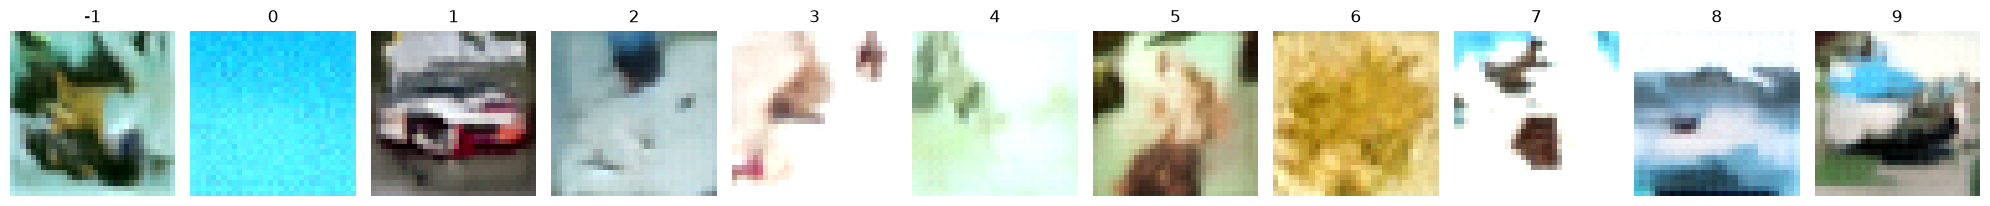

Epoch 11/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.6879 - classifier_loss: 0.8849 - loss: 0.0334 - noise_loss: 0.0315 - val_classifier_accuracy: 0.7058 - val_classifier_loss: 0.8198 - val_image_loss: 0.0857 - val_loss: 0.0343 - val_noise_loss: 0.0326 - learning_rate: 9.7044e-04
Steps: 100/100


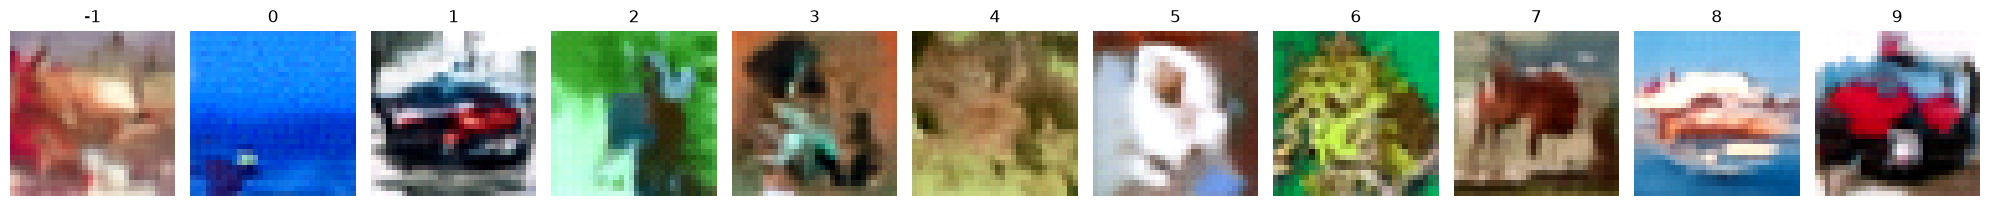

Epoch 12/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 49s 124ms/step - classifier_accuracy: 0.6989 - classifier_loss: 0.8566 - loss: 0.0329 - noise_loss: 0.0311 - val_classifier_accuracy: 0.7287 - val_classifier_loss: 0.7782 - val_image_loss: 0.0930 - val_loss: 0.0352 - val_noise_loss: 0.0335 - learning_rate: 9.6489e-04
Steps: 100/100


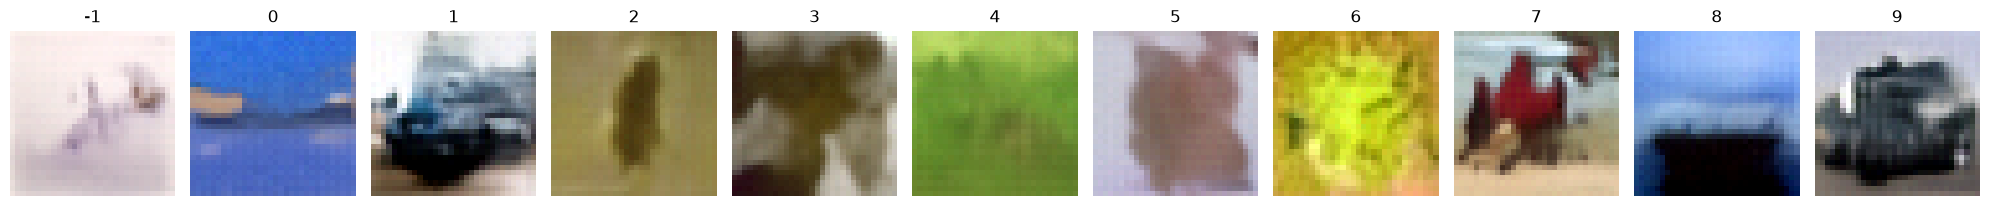

Epoch 13/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.7065 - classifier_loss: 0.8347 - loss: 0.0328 - noise_loss: 0.0310 - val_classifier_accuracy: 0.7391 - val_classifier_loss: 0.7448 - val_image_loss: 0.0930 - val_loss: 0.0342 - val_noise_loss: 0.0326 - learning_rate: 9.5888e-04
Steps: 100/100


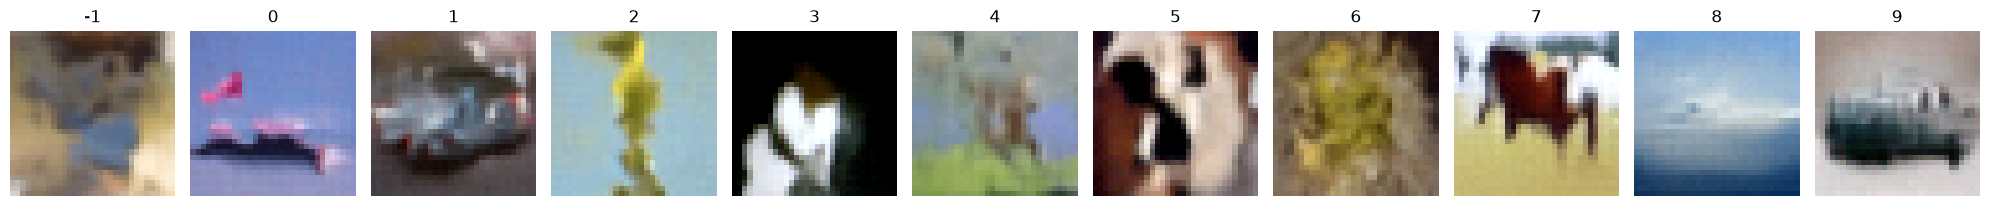

Epoch 14/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 123ms/step - classifier_accuracy: 0.7130 - classifier_loss: 0.8164 - loss: 0.0327 - noise_loss: 0.0310 - val_classifier_accuracy: 0.7262 - val_classifier_loss: 0.7673 - val_image_loss: 0.0891 - val_loss: 0.0338 - val_noise_loss: 0.0322 - learning_rate: 9.5241e-04
Steps: 100/100


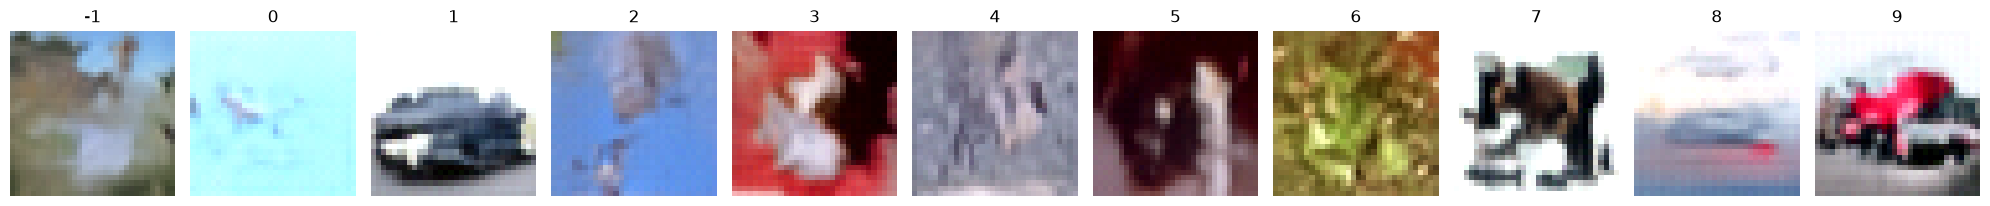

Epoch 15/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.7243 - classifier_loss: 0.7889 - loss: 0.0324 - noise_loss: 0.0307 - val_classifier_accuracy: 0.7551 - val_classifier_loss: 0.6988 - val_image_loss: 0.0870 - val_loss: 0.0340 - val_noise_loss: 0.0325 - learning_rate: 9.4550e-04
Steps: 100/100


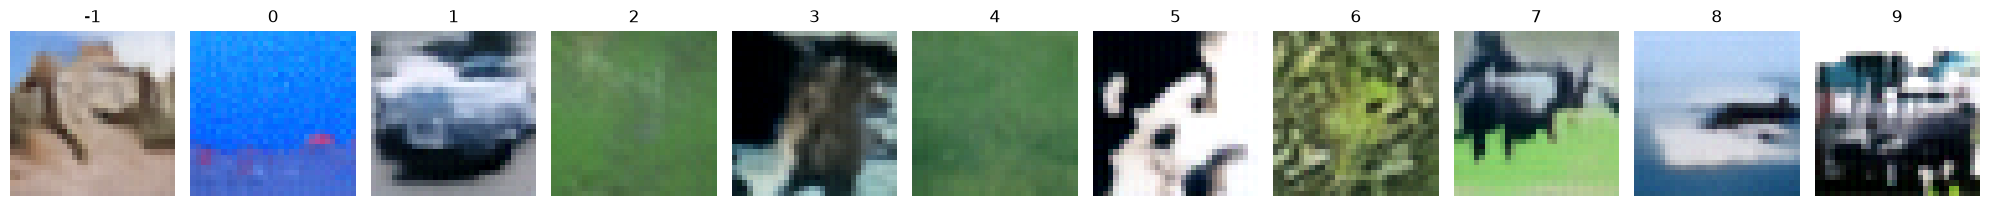

Epoch 16/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 49s 124ms/step - classifier_accuracy: 0.7288 - classifier_loss: 0.7731 - loss: 0.0324 - noise_loss: 0.0307 - val_classifier_accuracy: 0.7524 - val_classifier_loss: 0.6961 - val_image_loss: 0.0910 - val_loss: 0.0342 - val_noise_loss: 0.0327 - learning_rate: 9.3815e-04
Steps: 100/100


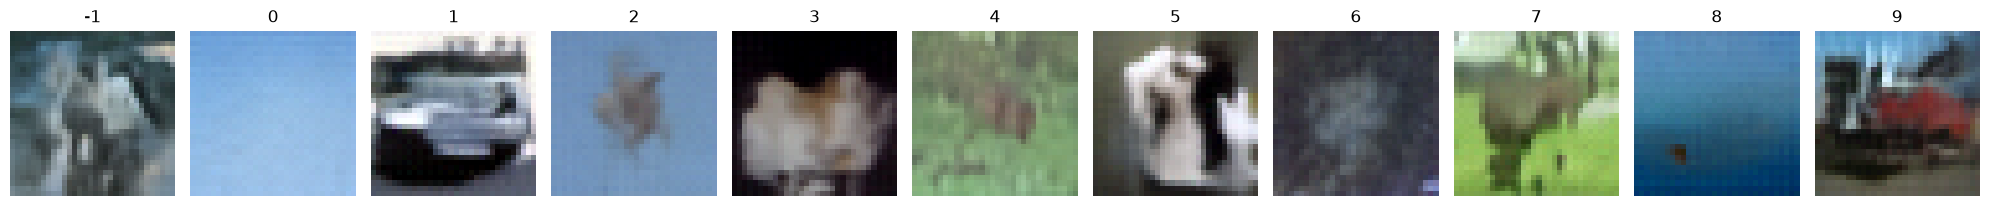

Epoch 17/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.7373 - classifier_loss: 0.7509 - loss: 0.0324 - noise_loss: 0.0308 - val_classifier_accuracy: 0.7595 - val_classifier_loss: 0.6902 - val_image_loss: 0.0889 - val_loss: 0.0333 - val_noise_loss: 0.0318 - learning_rate: 9.3037e-04
Steps: 100/100


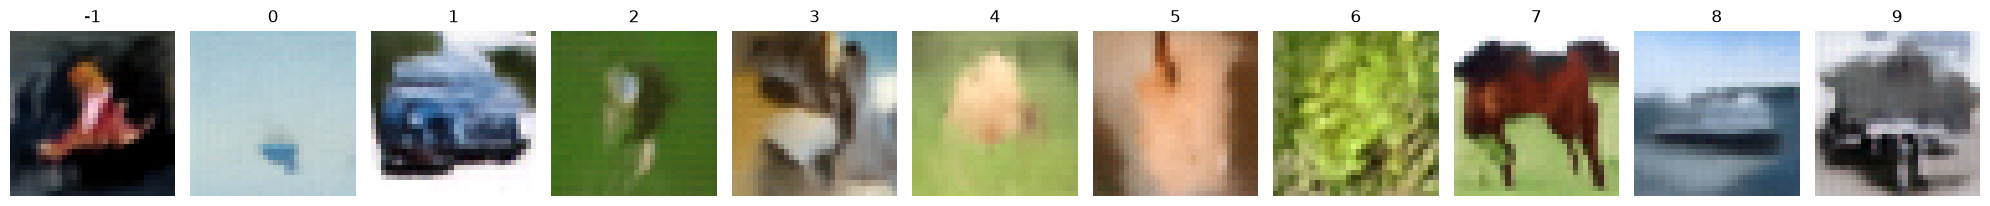

Epoch 18/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.7433 - classifier_loss: 0.7295 - loss: 0.0321 - noise_loss: 0.0306 - val_classifier_accuracy: 0.7506 - val_classifier_loss: 0.7094 - val_image_loss: 0.0890 - val_loss: 0.0344 - val_noise_loss: 0.0329 - learning_rate: 9.2216e-04
Steps: 100/100


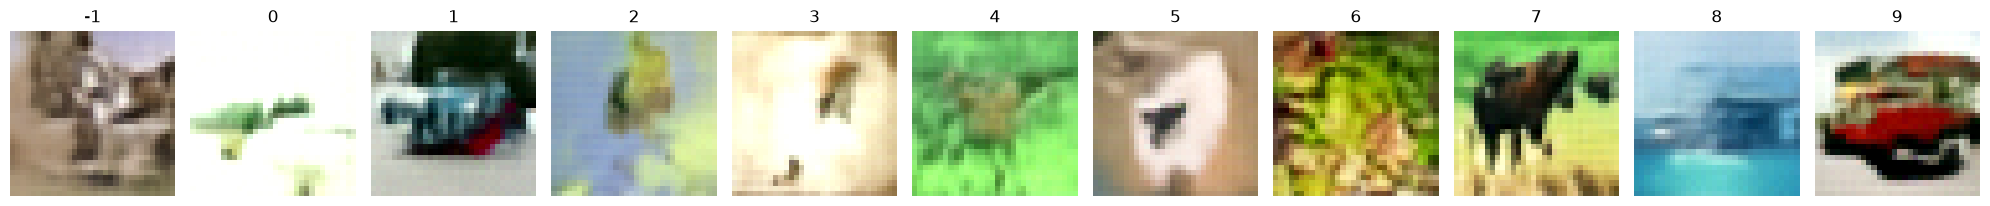

Epoch 19/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 46s 118ms/step - classifier_accuracy: 0.7497 - classifier_loss: 0.7134 - loss: 0.0324 - noise_loss: 0.0309 - val_classifier_accuracy: 0.7717 - val_classifier_loss: 0.6539 - val_image_loss: 0.0865 - val_loss: 0.0334 - val_noise_loss: 0.0320 - learning_rate: 9.1354e-04
Steps: 100/100


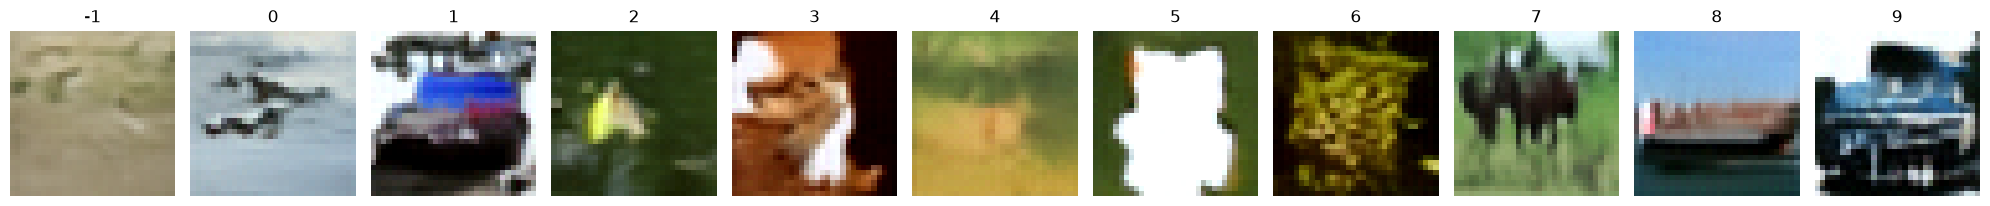

Epoch 20/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 55s 140ms/step - classifier_accuracy: 0.7561 - classifier_loss: 0.6943 - loss: 0.0318 - noise_loss: 0.0303 - val_classifier_accuracy: 0.7683 - val_classifier_loss: 0.6696 - val_image_loss: 0.0885 - val_loss: 0.0339 - val_noise_loss: 0.0325 - learning_rate: 9.0451e-04
Steps: 100/100


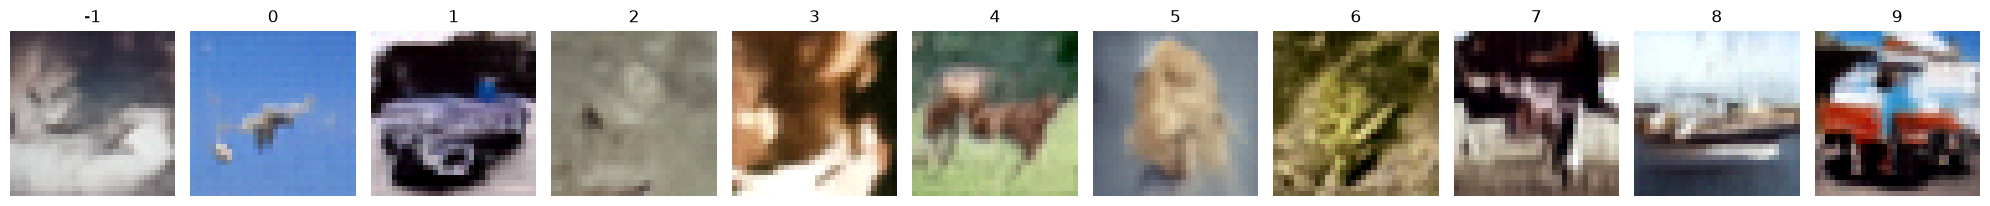

Epoch 21/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 55s 140ms/step - classifier_accuracy: 0.7606 - classifier_loss: 0.6807 - loss: 0.0317 - noise_loss: 0.0302 - val_classifier_accuracy: 0.7745 - val_classifier_loss: 0.6695 - val_image_loss: 0.0904 - val_loss: 0.0331 - val_noise_loss: 0.0317 - learning_rate: 8.9508e-04
Steps: 100/100


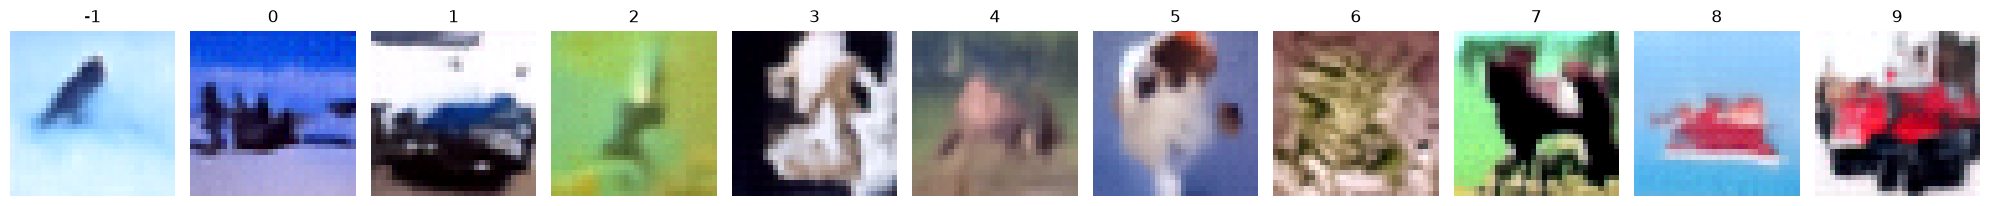

Epoch 22/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 58s 149ms/step - classifier_accuracy: 0.7683 - classifier_loss: 0.6595 - loss: 0.0317 - noise_loss: 0.0303 - val_classifier_accuracy: 0.7648 - val_classifier_loss: 0.6775 - val_image_loss: 0.0810 - val_loss: 0.0342 - val_noise_loss: 0.0327 - learning_rate: 8.8526e-04
Steps: 100/100


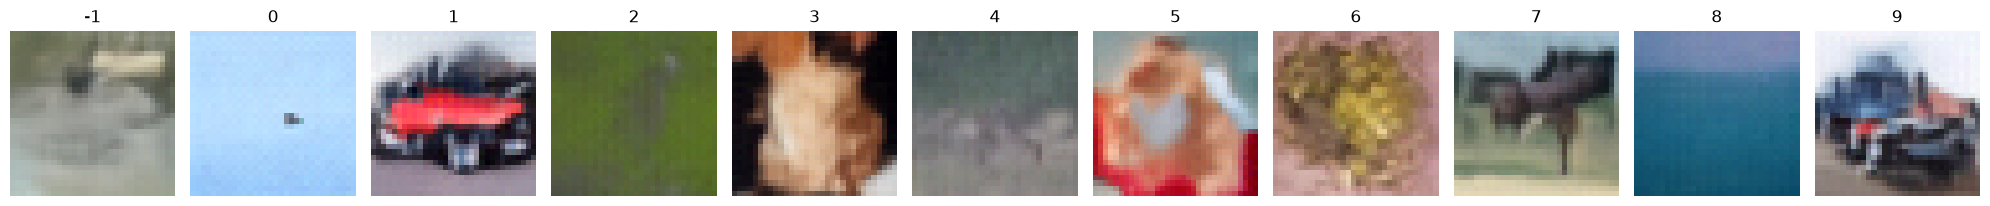

Epoch 23/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 57s 146ms/step - classifier_accuracy: 0.7748 - classifier_loss: 0.6476 - loss: 0.0319 - noise_loss: 0.0305 - val_classifier_accuracy: 0.7838 - val_classifier_loss: 0.6367 - val_image_loss: 0.0875 - val_loss: 0.0339 - val_noise_loss: 0.0325 - learning_rate: 8.7506e-04
Steps: 100/100


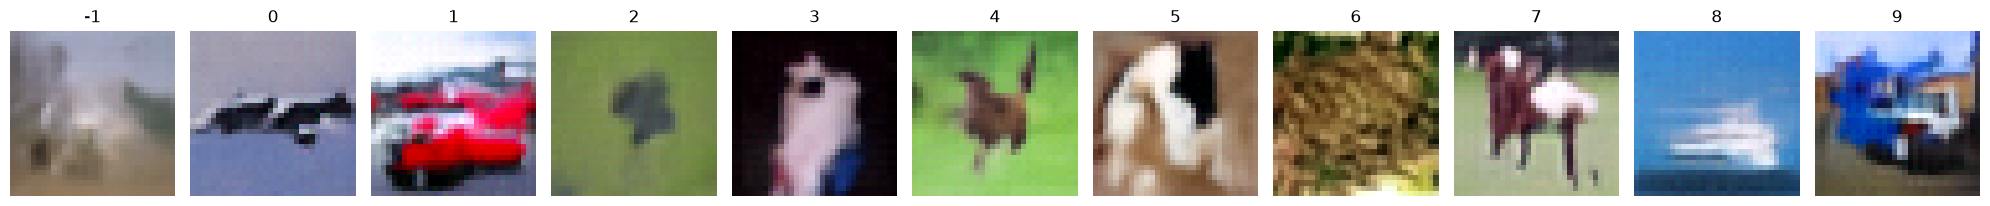

Epoch 24/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 57s 146ms/step - classifier_accuracy: 0.7812 - classifier_loss: 0.6280 - loss: 0.0314 - noise_loss: 0.0300 - val_classifier_accuracy: 0.7775 - val_classifier_loss: 0.6465 - val_image_loss: 0.0828 - val_loss: 0.0338 - val_noise_loss: 0.0324 - learning_rate: 8.6448e-04
Steps: 100/100


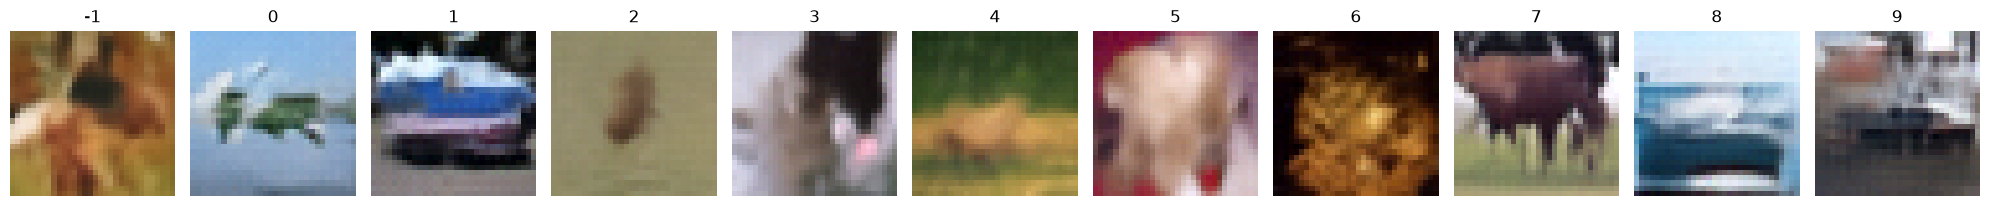

Epoch 25/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 57s 145ms/step - classifier_accuracy: 0.7833 - classifier_loss: 0.6191 - loss: 0.0318 - noise_loss: 0.0305 - val_classifier_accuracy: 0.7676 - val_classifier_loss: 0.6735 - val_image_loss: 0.0886 - val_loss: 0.0329 - val_noise_loss: 0.0315 - learning_rate: 8.5355e-04
Steps: 100/100


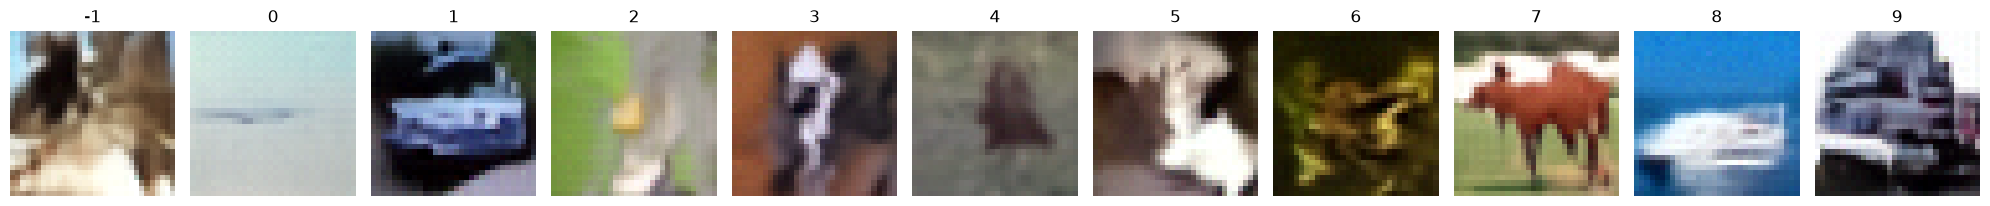

Epoch 26/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 55s 142ms/step - classifier_accuracy: 0.7924 - classifier_loss: 0.5988 - loss: 0.0315 - noise_loss: 0.0302 - val_classifier_accuracy: 0.7592 - val_classifier_loss: 0.7351 - val_image_loss: 0.0854 - val_loss: 0.0332 - val_noise_loss: 0.0317 - learning_rate: 8.4227e-04
Steps: 100/100


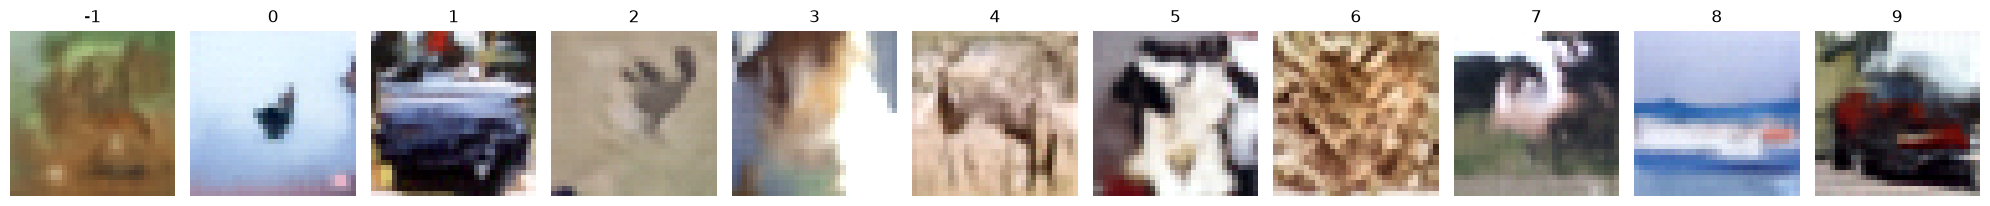

Epoch 27/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.7958 - classifier_loss: 0.5829 - loss: 0.0315 - noise_loss: 0.0302 - val_classifier_accuracy: 0.7717 - val_classifier_loss: 0.6693 - val_image_loss: 0.0854 - val_loss: 0.0338 - val_noise_loss: 0.0324 - learning_rate: 8.3066e-04
Steps: 100/100


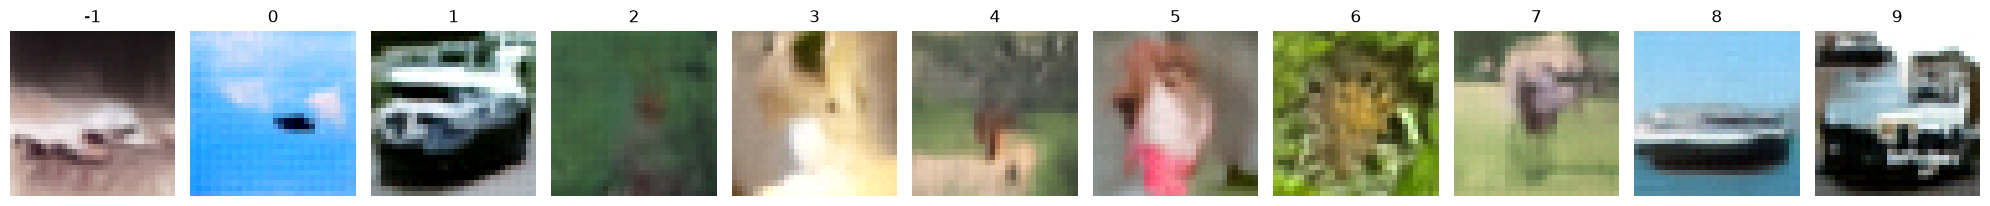

Epoch 28/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.7986 - classifier_loss: 0.5738 - loss: 0.0313 - noise_loss: 0.0301 - val_classifier_accuracy: 0.7946 - val_classifier_loss: 0.6031 - val_image_loss: 0.0833 - val_loss: 0.0331 - val_noise_loss: 0.0318 - learning_rate: 8.1871e-04
Steps: 100/100


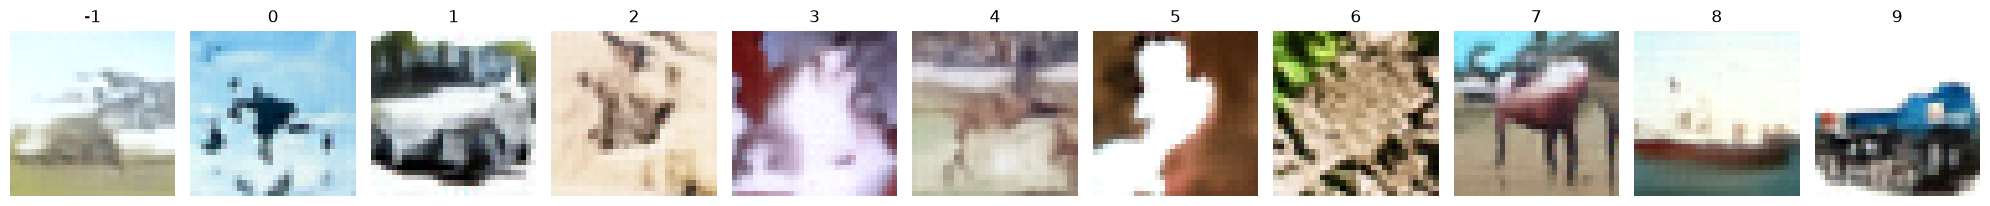

Epoch 29/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.8072 - classifier_loss: 0.5523 - loss: 0.0312 - noise_loss: 0.0300 - val_classifier_accuracy: 0.7768 - val_classifier_loss: 0.6998 - val_image_loss: 0.0834 - val_loss: 0.0336 - val_noise_loss: 0.0321 - learning_rate: 8.0645e-04
Steps: 100/100


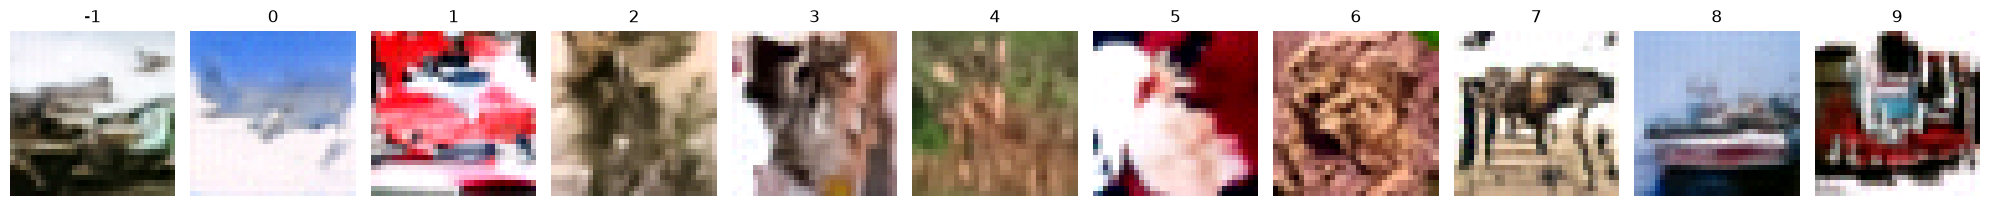

Epoch 30/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.8109 - classifier_loss: 0.5401 - loss: 0.0312 - noise_loss: 0.0300 - val_classifier_accuracy: 0.7951 - val_classifier_loss: 0.6176 - val_image_loss: 0.0790 - val_loss: 0.0333 - val_noise_loss: 0.0320 - learning_rate: 7.9389e-04
Steps: 100/100


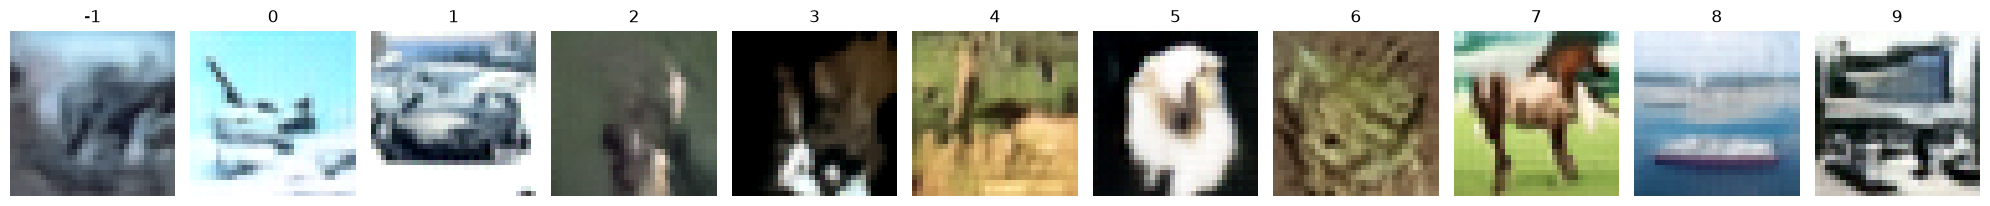

Epoch 31/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 123ms/step - classifier_accuracy: 0.8148 - classifier_loss: 0.5274 - loss: 0.0308 - noise_loss: 0.0296 - val_classifier_accuracy: 0.8051 - val_classifier_loss: 0.5819 - val_image_loss: 0.0856 - val_loss: 0.0325 - val_noise_loss: 0.0312 - learning_rate: 7.8104e-04
Steps: 100/100


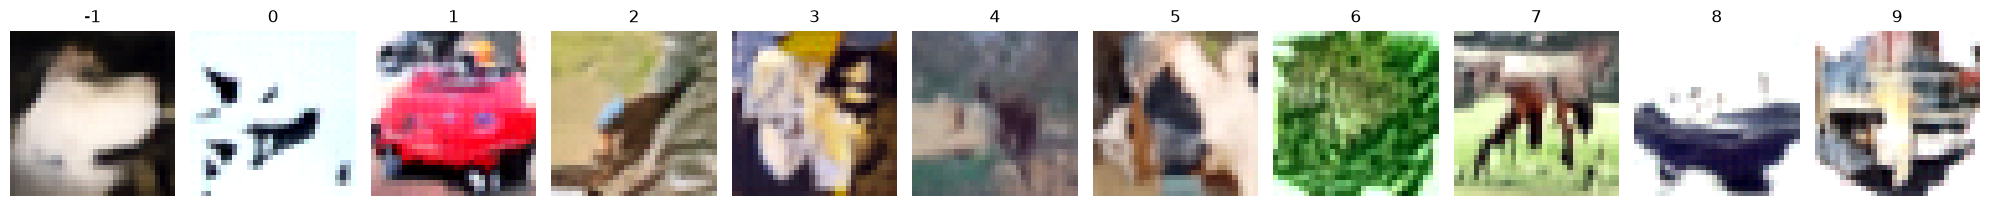

Epoch 32/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 123ms/step - classifier_accuracy: 0.8230 - classifier_loss: 0.5099 - loss: 0.0311 - noise_loss: 0.0300 - val_classifier_accuracy: 0.7866 - val_classifier_loss: 0.6489 - val_image_loss: 0.0842 - val_loss: 0.0340 - val_noise_loss: 0.0326 - learning_rate: 7.6791e-04
Steps: 100/100


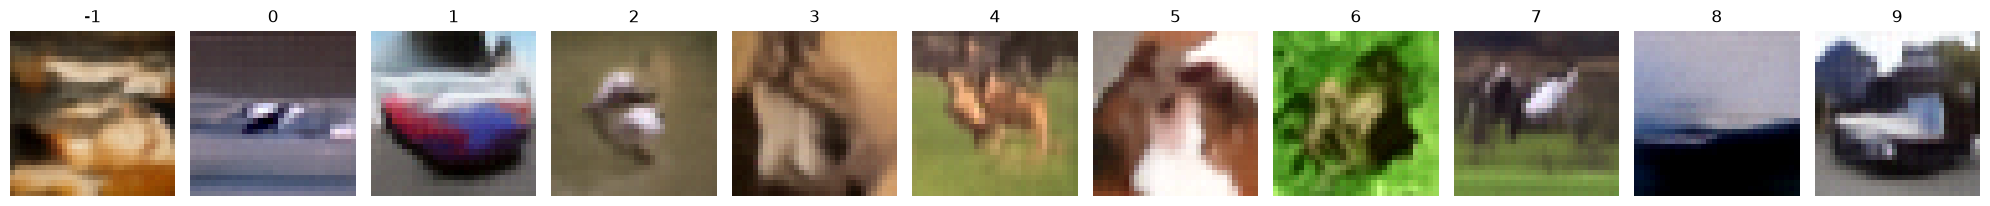

Epoch 33/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.8236 - classifier_loss: 0.5061 - loss: 0.0311 - noise_loss: 0.0300 - val_classifier_accuracy: 0.7830 - val_classifier_loss: 0.6542 - val_image_loss: 0.0865 - val_loss: 0.0334 - val_noise_loss: 0.0319 - learning_rate: 7.5452e-04
Steps: 100/100


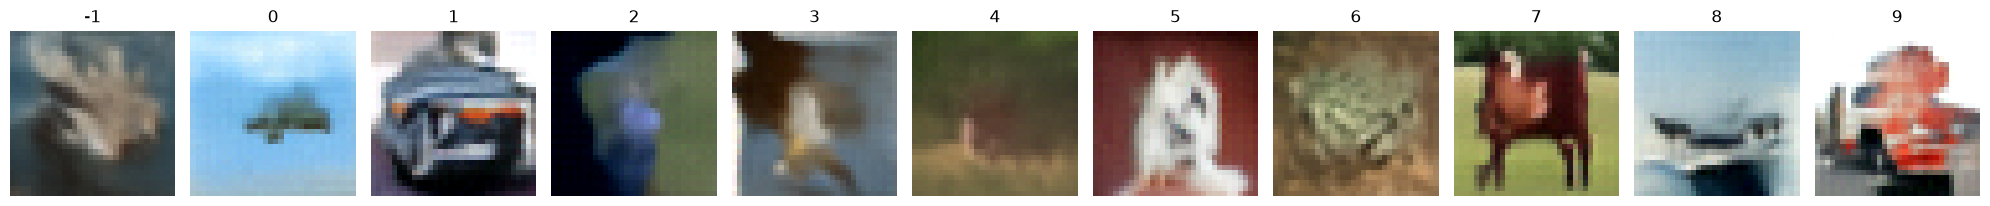

Epoch 34/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.8276 - classifier_loss: 0.4871 - loss: 0.0307 - noise_loss: 0.0296 - val_classifier_accuracy: 0.7983 - val_classifier_loss: 0.6229 - val_image_loss: 0.0846 - val_loss: 0.0339 - val_noise_loss: 0.0325 - learning_rate: 7.4088e-04
Steps: 100/100


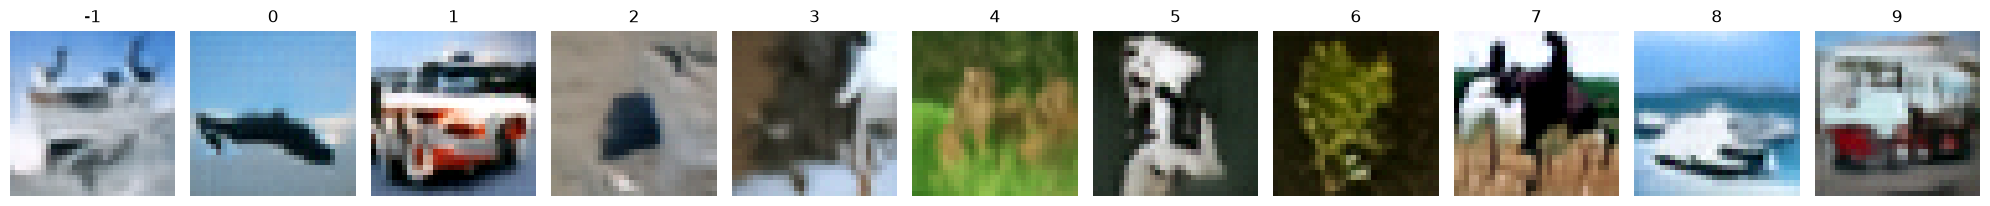

Epoch 35/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.8333 - classifier_loss: 0.4724 - loss: 0.0311 - noise_loss: 0.0301 - val_classifier_accuracy: 0.7849 - val_classifier_loss: 0.6274 - val_image_loss: 0.0840 - val_loss: 0.0326 - val_noise_loss: 0.0313 - learning_rate: 7.2700e-04
Steps: 100/100


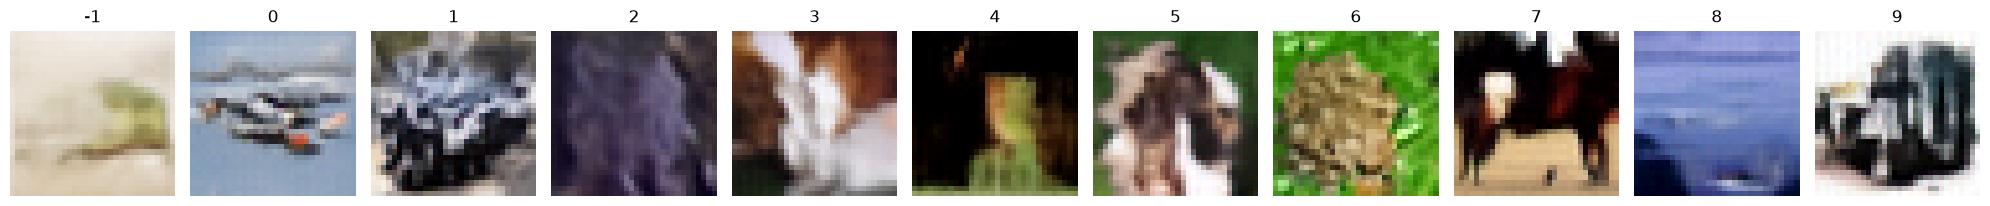

Epoch 36/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.8369 - classifier_loss: 0.4625 - loss: 0.0309 - noise_loss: 0.0300 - val_classifier_accuracy: 0.7975 - val_classifier_loss: 0.6320 - val_image_loss: 0.0826 - val_loss: 0.0330 - val_noise_loss: 0.0316 - learning_rate: 7.1289e-04
Steps: 100/100


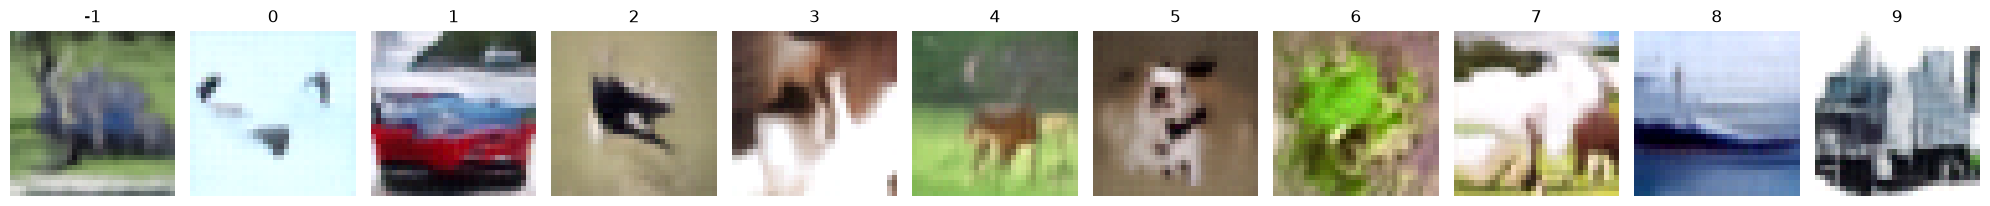

Epoch 37/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.8432 - classifier_loss: 0.4441 - loss: 0.0305 - noise_loss: 0.0296 - val_classifier_accuracy: 0.8008 - val_classifier_loss: 0.6051 - val_image_loss: 0.0795 - val_loss: 0.0335 - val_noise_loss: 0.0322 - learning_rate: 6.9857e-04
Steps: 100/100


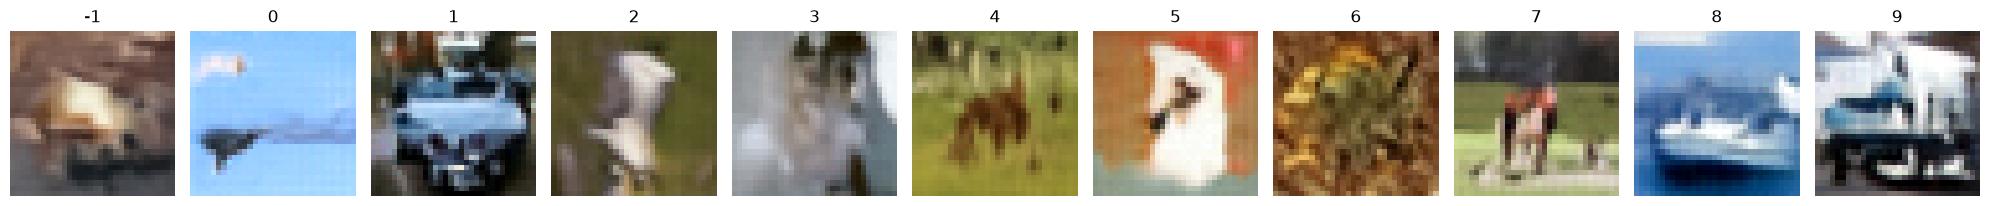

Epoch 38/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.8459 - classifier_loss: 0.4336 - loss: 0.0308 - noise_loss: 0.0299 - val_classifier_accuracy: 0.8037 - val_classifier_loss: 0.5940 - val_image_loss: 0.0820 - val_loss: 0.0323 - val_noise_loss: 0.0310 - learning_rate: 6.8406e-04
Steps: 100/100


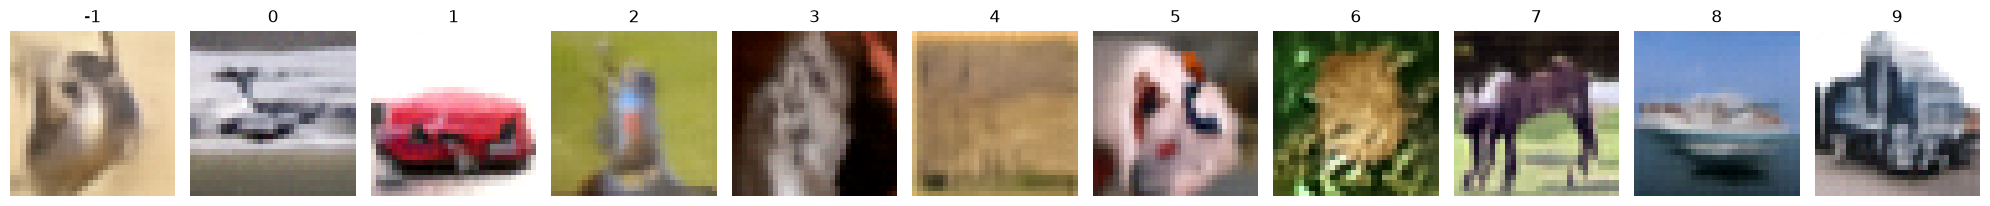

Epoch 39/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 48s 124ms/step - classifier_accuracy: 0.8535 - classifier_loss: 0.4173 - loss: 0.0307 - noise_loss: 0.0298 - val_classifier_accuracy: 0.8023 - val_classifier_loss: 0.6393 - val_image_loss: 0.0796 - val_loss: 0.0336 - val_noise_loss: 0.0322 - learning_rate: 6.6937e-04
Steps: 100/100


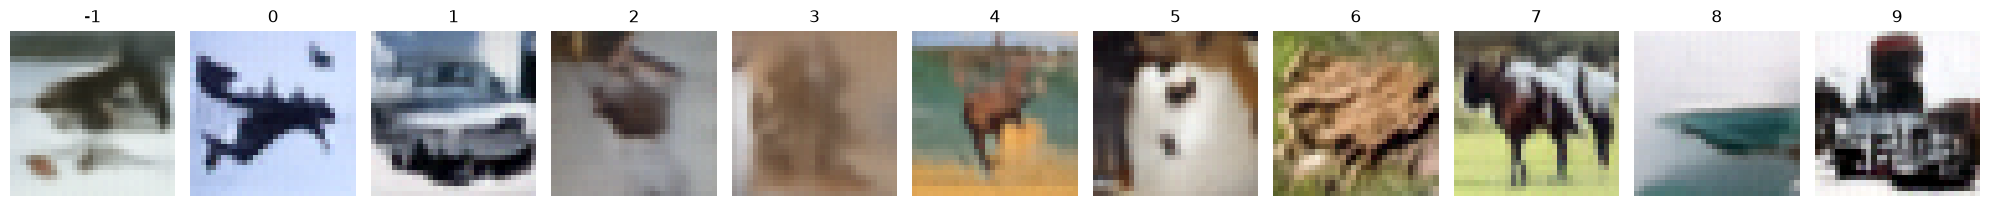

Epoch 40/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.8552 - classifier_loss: 0.4125 - loss: 0.0307 - noise_loss: 0.0298 - val_classifier_accuracy: 0.8022 - val_classifier_loss: 0.6436 - val_image_loss: 0.0812 - val_loss: 0.0336 - val_noise_loss: 0.0322 - learning_rate: 6.5451e-04
Steps: 100/100


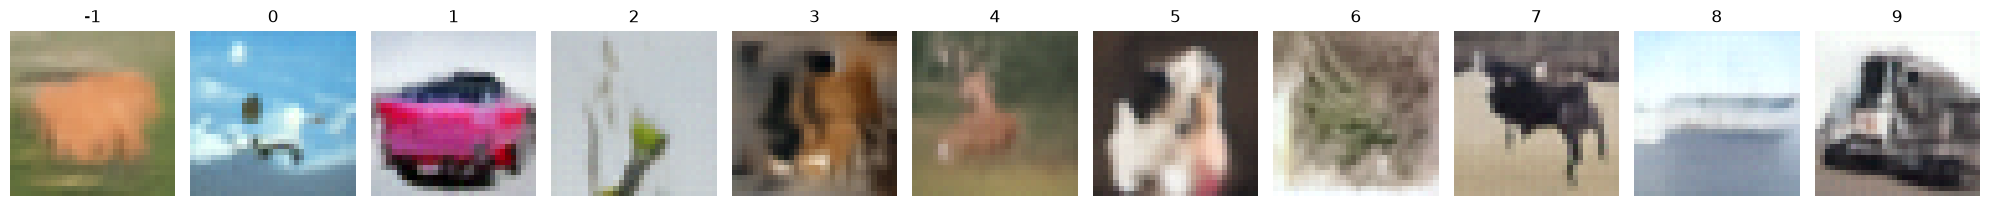

Epoch 41/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.8622 - classifier_loss: 0.3919 - loss: 0.0308 - noise_loss: 0.0299 - val_classifier_accuracy: 0.8119 - val_classifier_loss: 0.6067 - val_image_loss: 0.0775 - val_loss: 0.0325 - val_noise_loss: 0.0312 - learning_rate: 6.3950e-04
Steps: 100/100


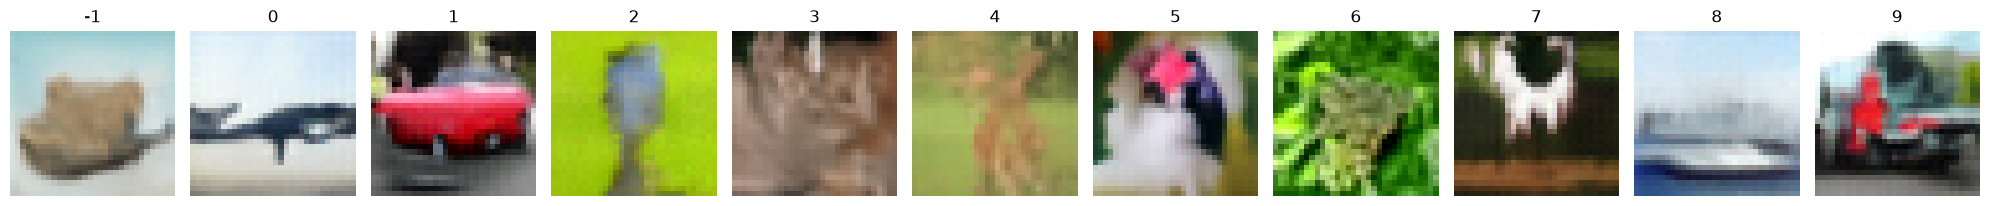

Epoch 42/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.8659 - classifier_loss: 0.3852 - loss: 0.0306 - noise_loss: 0.0297 - val_classifier_accuracy: 0.8001 - val_classifier_loss: 0.6575 - val_image_loss: 0.0807 - val_loss: 0.0336 - val_noise_loss: 0.0322 - learning_rate: 6.2435e-04
Steps: 100/100


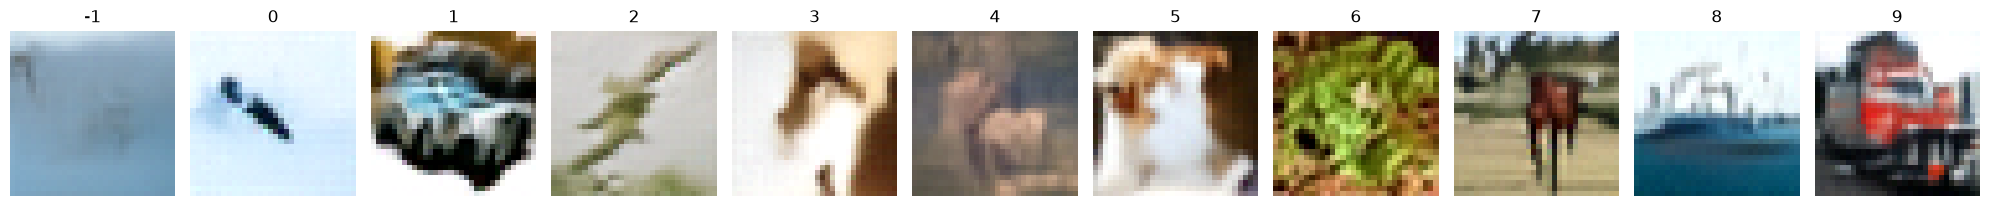

Epoch 43/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.8670 - classifier_loss: 0.3702 - loss: 0.0305 - noise_loss: 0.0297 - val_classifier_accuracy: 0.8090 - val_classifier_loss: 0.6427 - val_image_loss: 0.0827 - val_loss: 0.0326 - val_noise_loss: 0.0312 - learning_rate: 6.0907e-04
Steps: 100/100


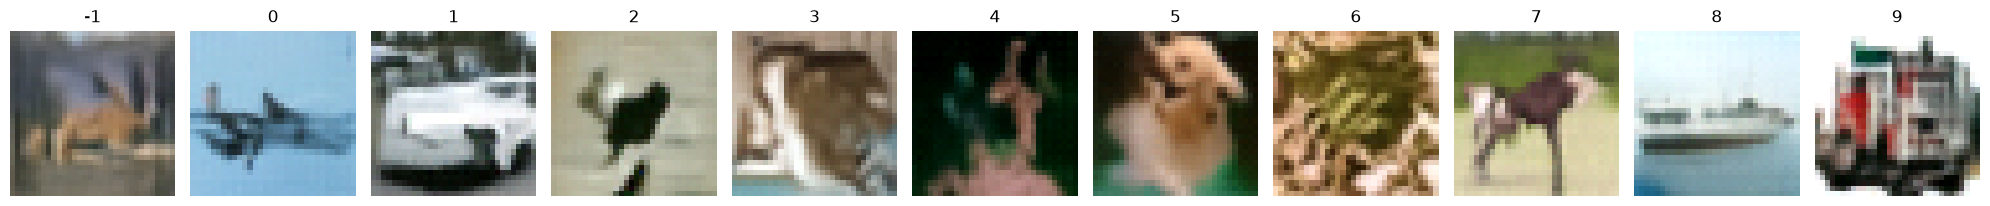

Epoch 44/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 104ms/step - classifier_accuracy: 0.8763 - classifier_loss: 0.3524 - loss: 0.0305 - noise_loss: 0.0297 - val_classifier_accuracy: 0.8103 - val_classifier_loss: 0.6247 - val_image_loss: 0.0764 - val_loss: 0.0325 - val_noise_loss: 0.0312 - learning_rate: 5.9369e-04
Steps: 100/100


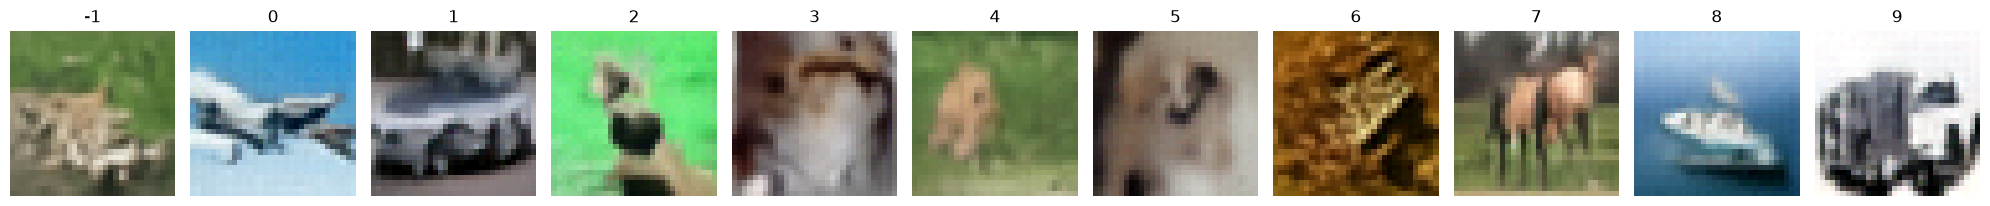

Epoch 45/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.8797 - classifier_loss: 0.3418 - loss: 0.0304 - noise_loss: 0.0297 - val_classifier_accuracy: 0.8021 - val_classifier_loss: 0.6475 - val_image_loss: 0.0764 - val_loss: 0.0333 - val_noise_loss: 0.0319 - learning_rate: 5.7822e-04
Steps: 100/100


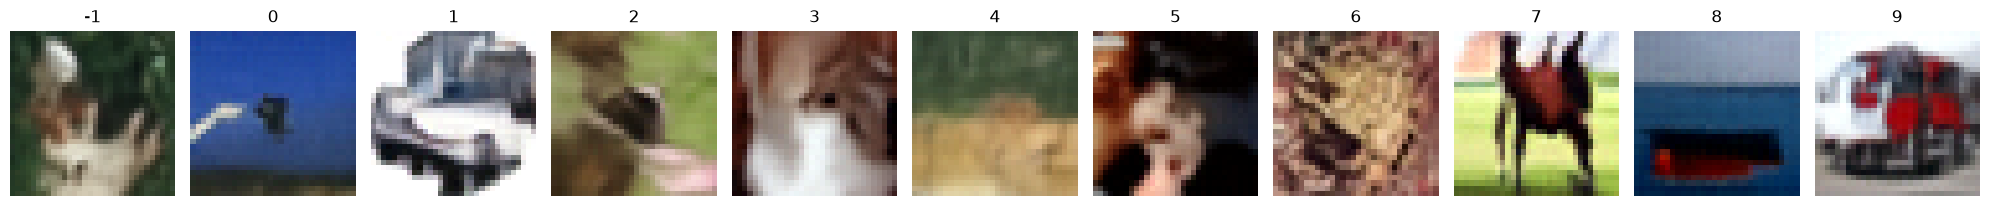

Epoch 46/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.8789 - classifier_loss: 0.3406 - loss: 0.0304 - noise_loss: 0.0297 - val_classifier_accuracy: 0.8081 - val_classifier_loss: 0.6381 - val_image_loss: 0.0764 - val_loss: 0.0329 - val_noise_loss: 0.0316 - learning_rate: 5.6267e-04
Steps: 100/100


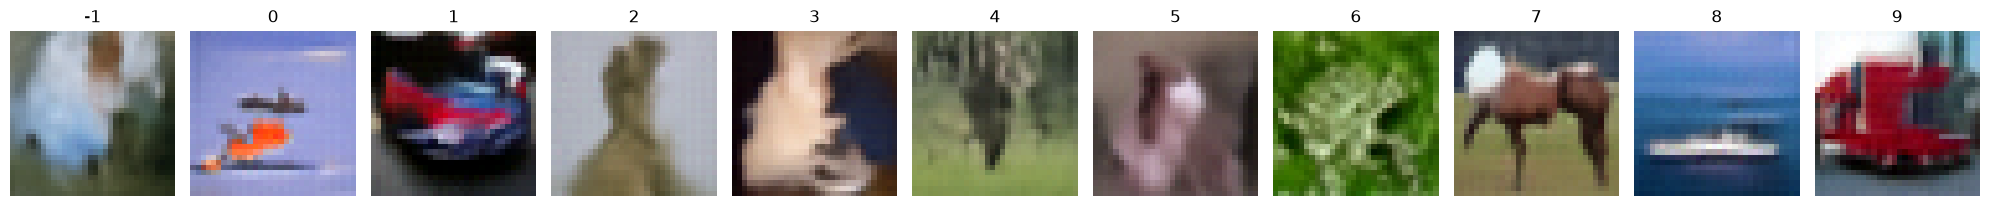

Epoch 47/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.8851 - classifier_loss: 0.3219 - loss: 0.0300 - noise_loss: 0.0293 - val_classifier_accuracy: 0.8058 - val_classifier_loss: 0.6829 - val_image_loss: 0.0771 - val_loss: 0.0331 - val_noise_loss: 0.0316 - learning_rate: 5.4705e-04
Steps: 100/100


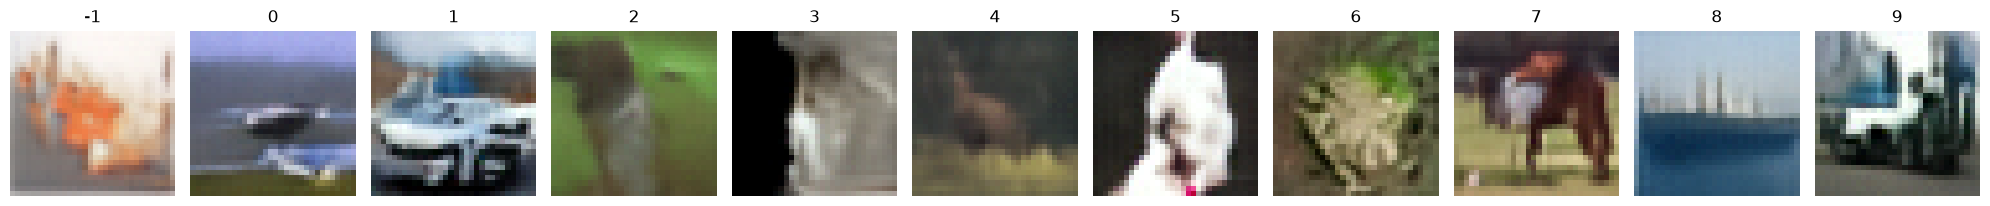

Epoch 48/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 104ms/step - classifier_accuracy: 0.8903 - classifier_loss: 0.3116 - loss: 0.0301 - noise_loss: 0.0294 - val_classifier_accuracy: 0.8028 - val_classifier_loss: 0.6828 - val_image_loss: 0.0785 - val_loss: 0.0336 - val_noise_loss: 0.0321 - learning_rate: 5.3140e-04
Steps: 100/100


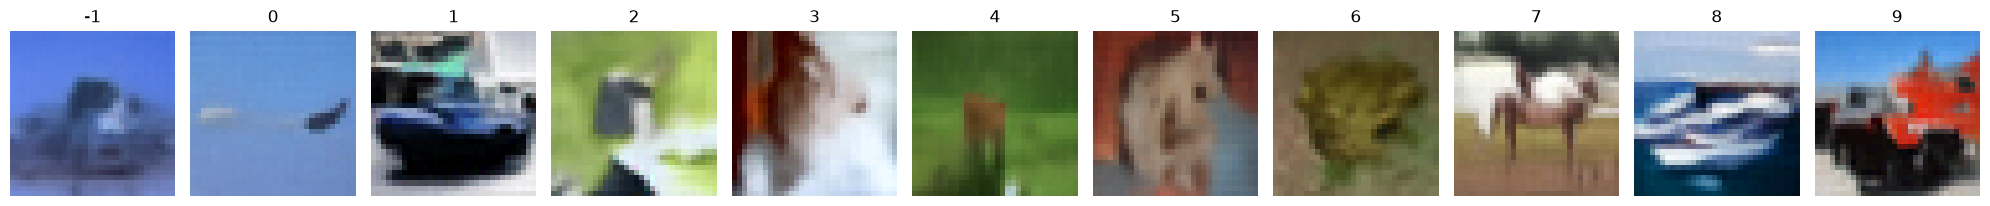

Epoch 49/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.8928 - classifier_loss: 0.2975 - loss: 0.0298 - noise_loss: 0.0292 - val_classifier_accuracy: 0.8128 - val_classifier_loss: 0.6425 - val_image_loss: 0.0777 - val_loss: 0.0332 - val_noise_loss: 0.0318 - learning_rate: 5.1571e-04
Steps: 100/100


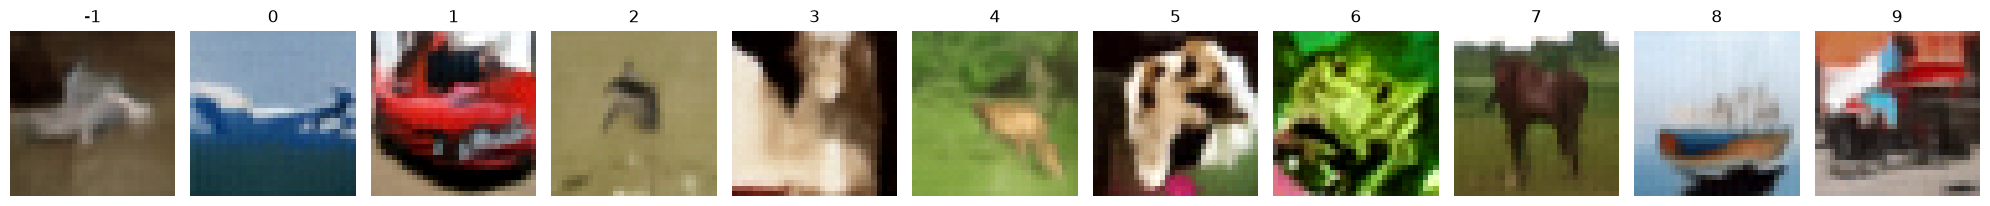

Epoch 50/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.8982 - classifier_loss: 0.2871 - loss: 0.0300 - noise_loss: 0.0294 - val_classifier_accuracy: 0.8069 - val_classifier_loss: 0.6832 - val_image_loss: 0.0786 - val_loss: 0.0328 - val_noise_loss: 0.0313 - learning_rate: 5.0000e-04
Steps: 100/100


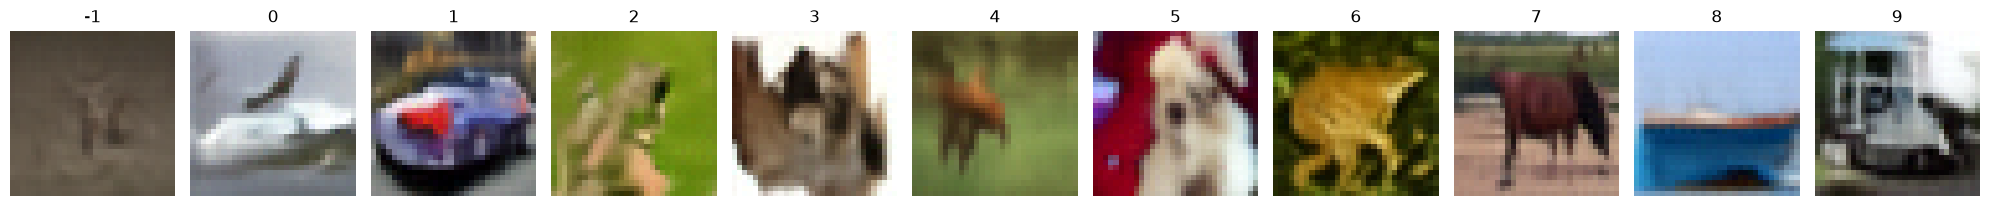

Epoch 51/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.9021 - classifier_loss: 0.2765 - loss: 0.0301 - noise_loss: 0.0295 - val_classifier_accuracy: 0.8047 - val_classifier_loss: 0.6846 - val_image_loss: 0.0790 - val_loss: 0.0328 - val_noise_loss: 0.0313 - learning_rate: 4.8429e-04
Steps: 100/100


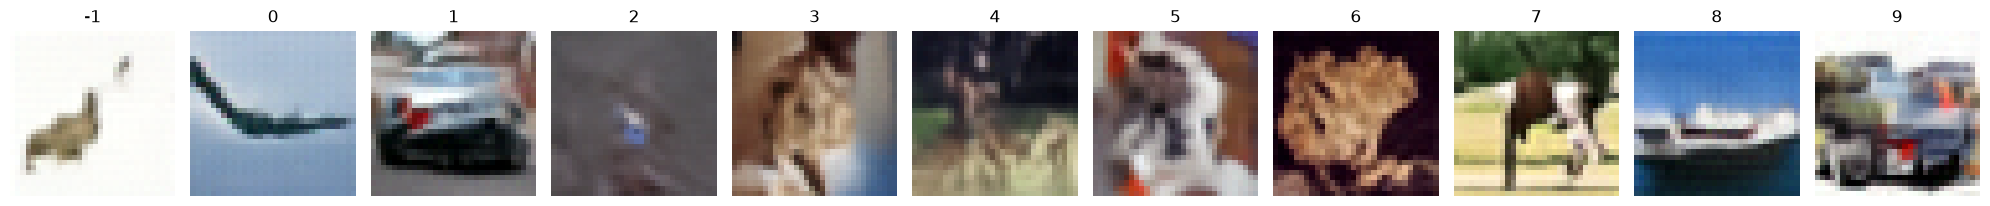

Epoch 52/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9049 - classifier_loss: 0.2723 - loss: 0.0297 - noise_loss: 0.0291 - val_classifier_accuracy: 0.8003 - val_classifier_loss: 0.7251 - val_image_loss: 0.0746 - val_loss: 0.0329 - val_noise_loss: 0.0314 - learning_rate: 4.6860e-04
Steps: 100/100


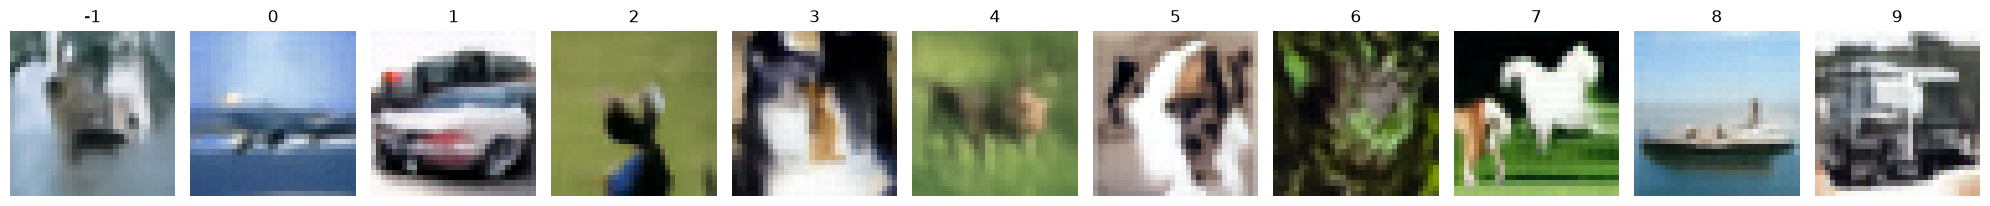

Epoch 53/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.9101 - classifier_loss: 0.2569 - loss: 0.0297 - noise_loss: 0.0291 - val_classifier_accuracy: 0.8061 - val_classifier_loss: 0.6975 - val_image_loss: 0.0742 - val_loss: 0.0326 - val_noise_loss: 0.0311 - learning_rate: 4.5295e-04
Steps: 100/100


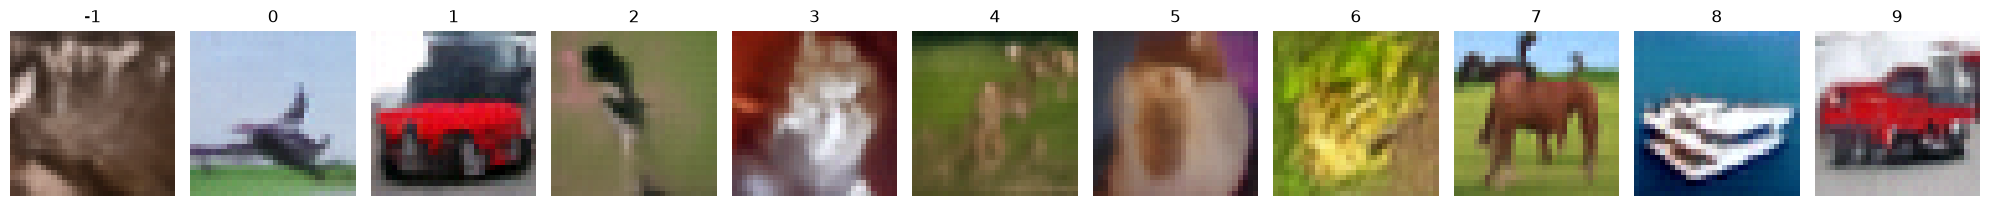

Epoch 54/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.9149 - classifier_loss: 0.2433 - loss: 0.0302 - noise_loss: 0.0297 - val_classifier_accuracy: 0.8105 - val_classifier_loss: 0.6937 - val_image_loss: 0.0750 - val_loss: 0.0328 - val_noise_loss: 0.0313 - learning_rate: 4.3733e-04
Steps: 100/100


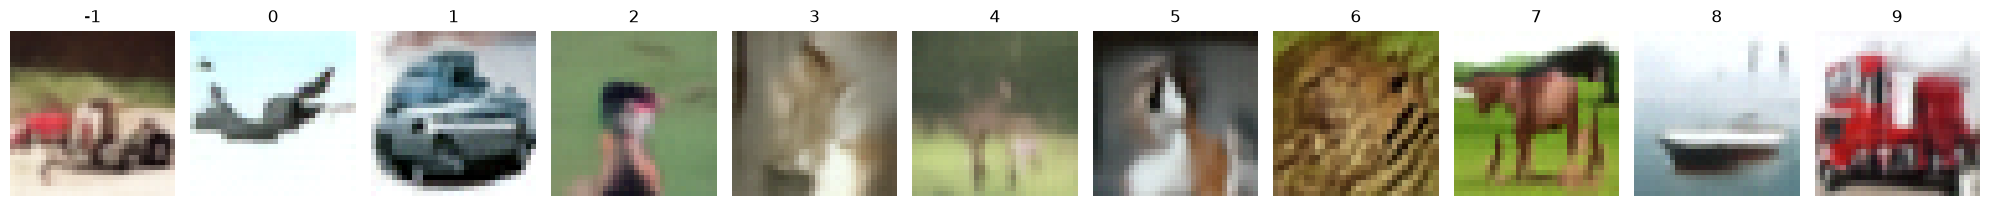

Epoch 55/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.9166 - classifier_loss: 0.2363 - loss: 0.0296 - noise_loss: 0.0291 - val_classifier_accuracy: 0.8162 - val_classifier_loss: 0.7130 - val_image_loss: 0.0748 - val_loss: 0.0323 - val_noise_loss: 0.0308 - learning_rate: 4.2178e-04
Steps: 100/100


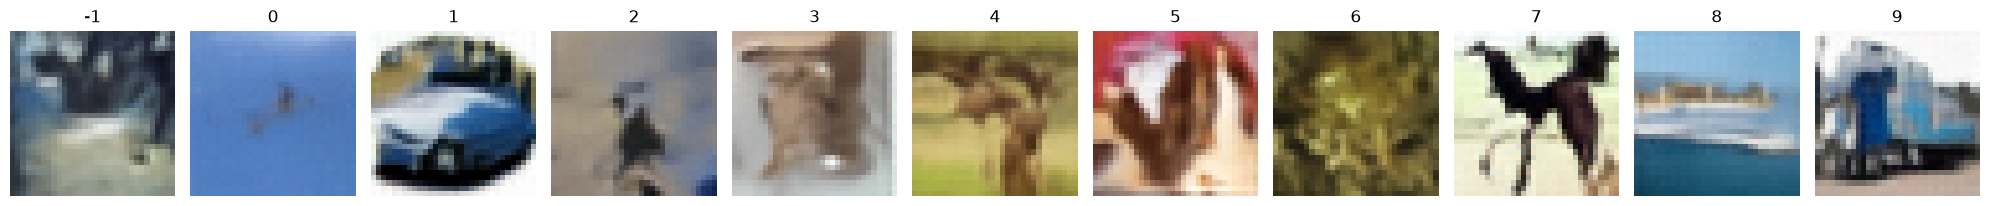

Epoch 56/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.9207 - classifier_loss: 0.2239 - loss: 0.0299 - noise_loss: 0.0295 - val_classifier_accuracy: 0.8097 - val_classifier_loss: 0.7255 - val_image_loss: 0.0762 - val_loss: 0.0333 - val_noise_loss: 0.0317 - learning_rate: 4.0631e-04
Steps: 100/100


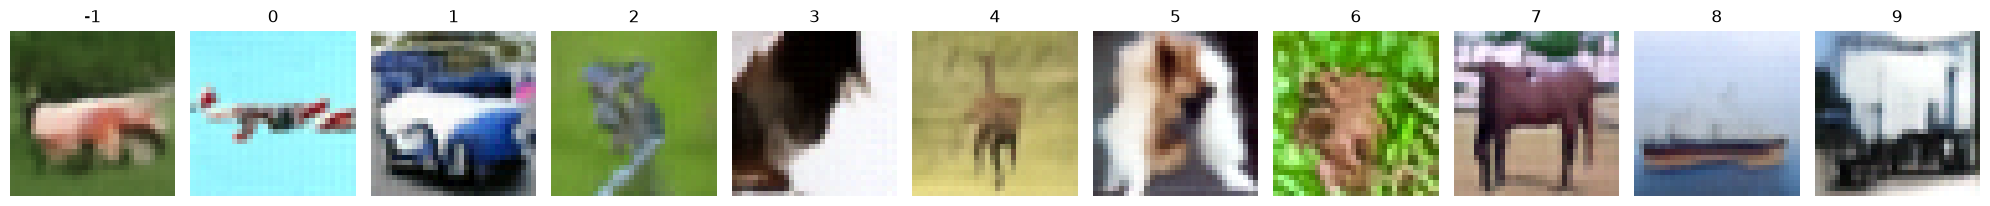

Epoch 57/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 38s 98ms/step - classifier_accuracy: 0.9238 - classifier_loss: 0.2173 - loss: 0.0300 - noise_loss: 0.0295 - val_classifier_accuracy: 0.8106 - val_classifier_loss: 0.7469 - val_image_loss: 0.0767 - val_loss: 0.0332 - val_noise_loss: 0.0316 - learning_rate: 3.9093e-04
Steps: 100/100


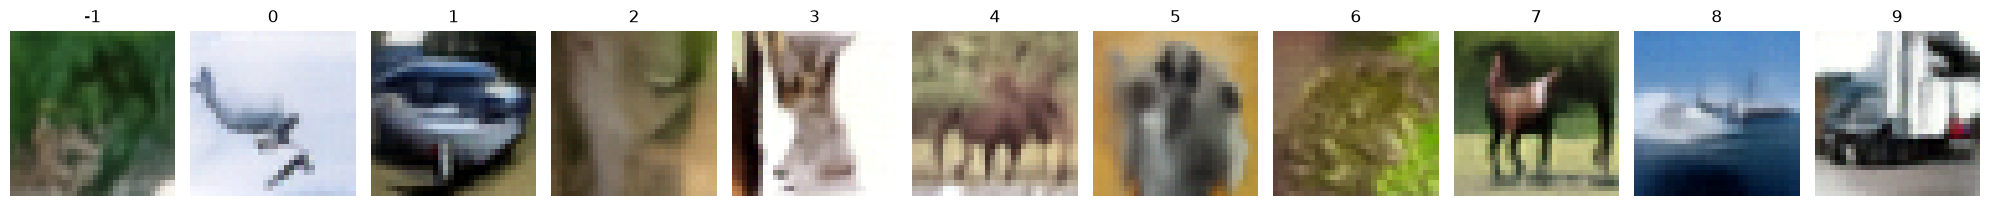

Epoch 58/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 38s 99ms/step - classifier_accuracy: 0.9251 - classifier_loss: 0.2089 - loss: 0.0298 - noise_loss: 0.0294 - val_classifier_accuracy: 0.8084 - val_classifier_loss: 0.7594 - val_image_loss: 0.0743 - val_loss: 0.0331 - val_noise_loss: 0.0314 - learning_rate: 3.7566e-04
Steps: 100/100


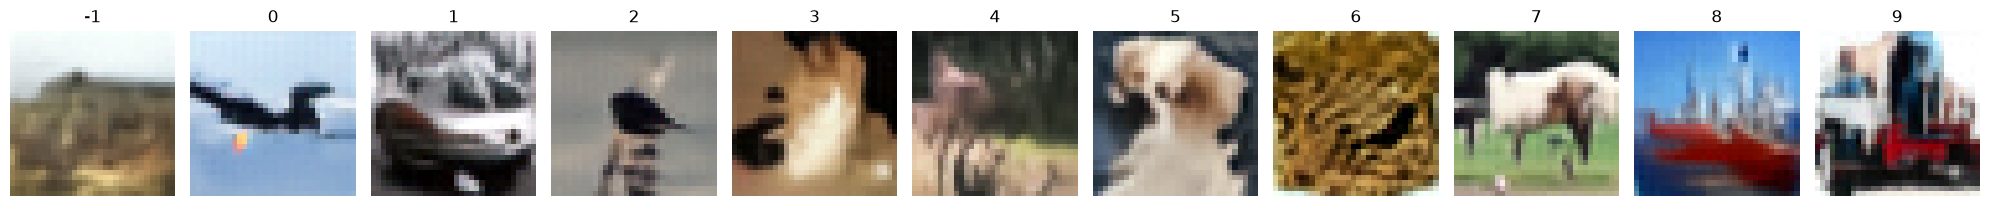

Epoch 59/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9290 - classifier_loss: 0.2007 - loss: 0.0298 - noise_loss: 0.0294 - val_classifier_accuracy: 0.8086 - val_classifier_loss: 0.7814 - val_image_loss: 0.0758 - val_loss: 0.0328 - val_noise_loss: 0.0311 - learning_rate: 3.6050e-04
Steps: 100/100


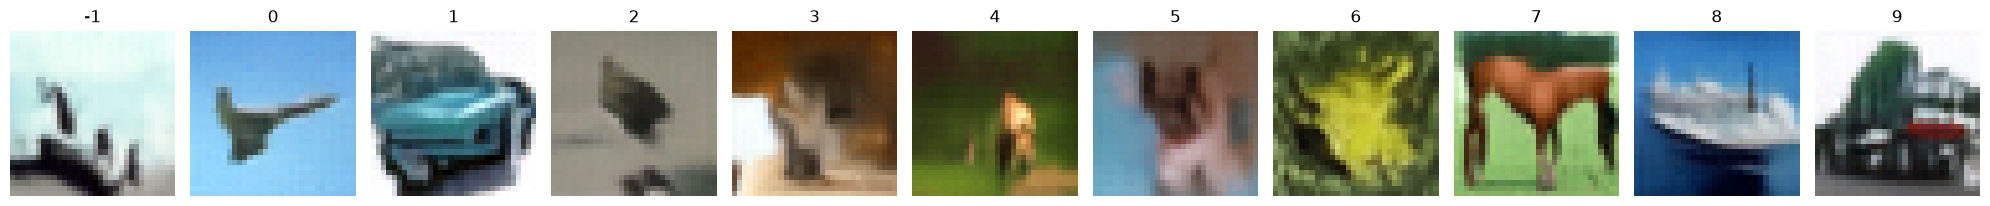

Epoch 60/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 38s 98ms/step - classifier_accuracy: 0.9341 - classifier_loss: 0.1917 - loss: 0.0296 - noise_loss: 0.0292 - val_classifier_accuracy: 0.8124 - val_classifier_loss: 0.7260 - val_image_loss: 0.0769 - val_loss: 0.0331 - val_noise_loss: 0.0315 - learning_rate: 3.4549e-04
Steps: 100/100


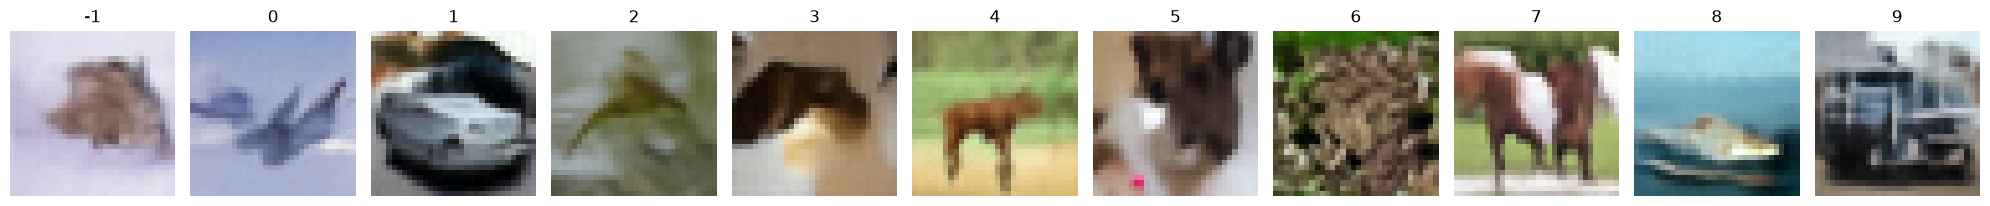

Epoch 61/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9369 - classifier_loss: 0.1787 - loss: 0.0296 - noise_loss: 0.0292 - val_classifier_accuracy: 0.8029 - val_classifier_loss: 0.7451 - val_image_loss: 0.0757 - val_loss: 0.0322 - val_noise_loss: 0.0306 - learning_rate: 3.3063e-04
Steps: 100/100


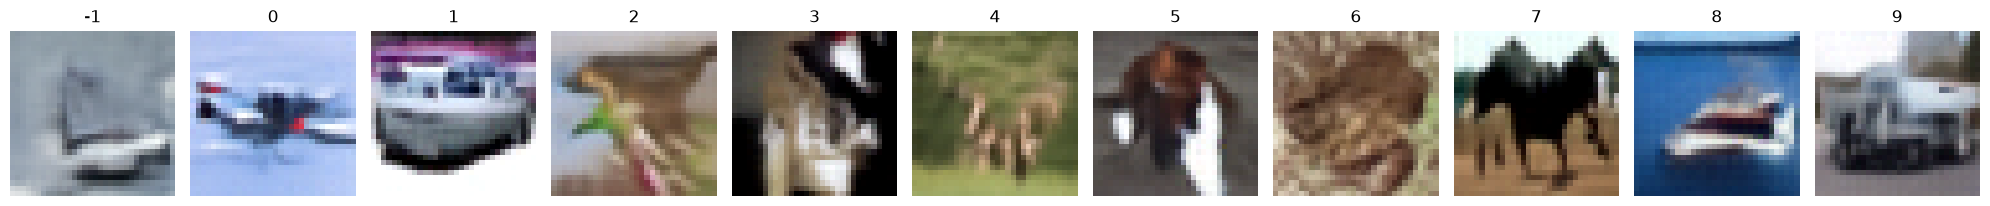

Epoch 62/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.9362 - classifier_loss: 0.1804 - loss: 0.0297 - noise_loss: 0.0293 - val_classifier_accuracy: 0.8145 - val_classifier_loss: 0.7617 - val_image_loss: 0.0731 - val_loss: 0.0326 - val_noise_loss: 0.0309 - learning_rate: 3.1594e-04
Steps: 100/100


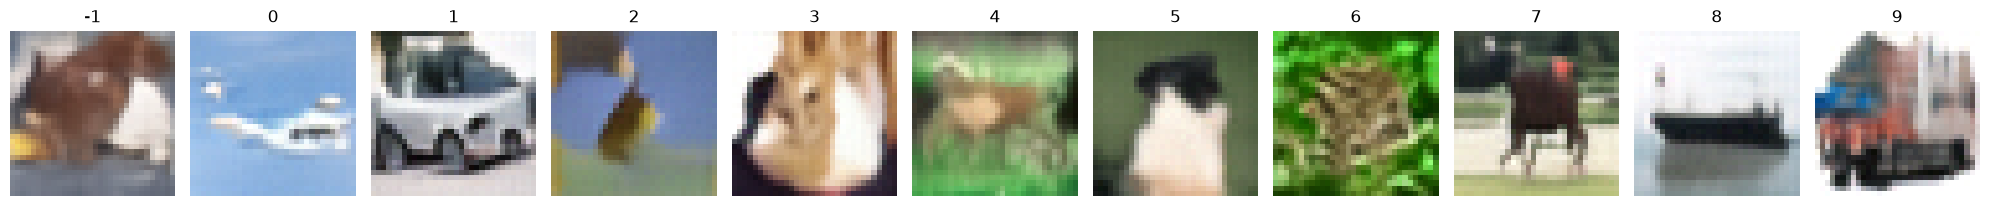

Epoch 63/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.9443 - classifier_loss: 0.1621 - loss: 0.0295 - noise_loss: 0.0292 - val_classifier_accuracy: 0.8113 - val_classifier_loss: 0.8121 - val_image_loss: 0.0758 - val_loss: 0.0327 - val_noise_loss: 0.0310 - learning_rate: 3.0143e-04
Steps: 100/100


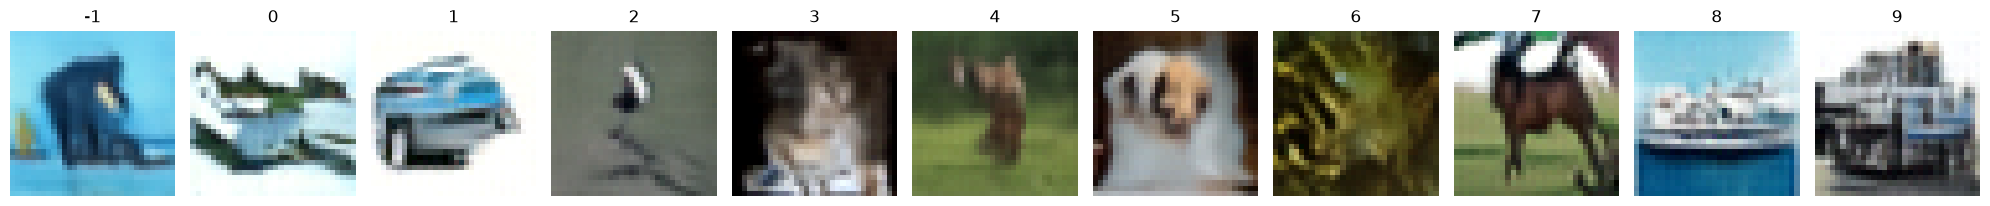

Epoch 64/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.9447 - classifier_loss: 0.1588 - loss: 0.0292 - noise_loss: 0.0289 - val_classifier_accuracy: 0.8144 - val_classifier_loss: 0.7723 - val_image_loss: 0.0734 - val_loss: 0.0340 - val_noise_loss: 0.0323 - learning_rate: 2.8711e-04
Steps: 100/100


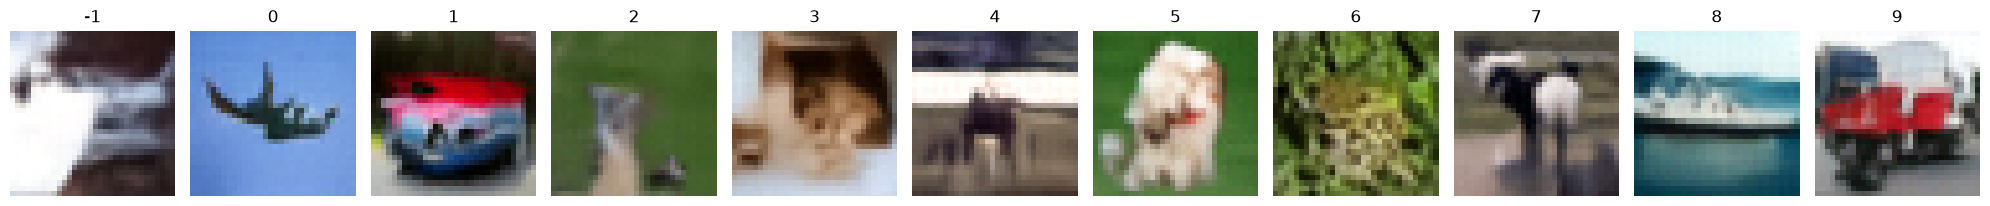

Epoch 65/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9475 - classifier_loss: 0.1524 - loss: 0.0295 - noise_loss: 0.0292 - val_classifier_accuracy: 0.8122 - val_classifier_loss: 0.8150 - val_image_loss: 0.0728 - val_loss: 0.0336 - val_noise_loss: 0.0318 - learning_rate: 2.7300e-04
Steps: 100/100


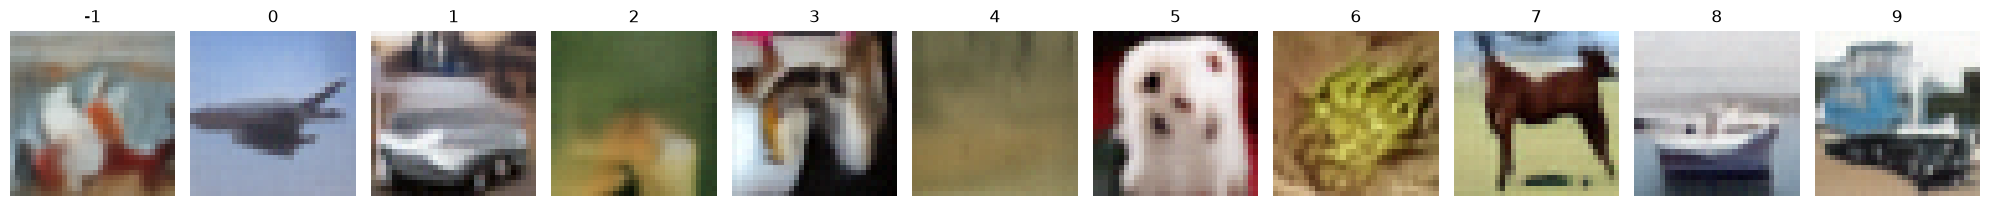

Epoch 66/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 102ms/step - classifier_accuracy: 0.9499 - classifier_loss: 0.1417 - loss: 0.0293 - noise_loss: 0.0290 - val_classifier_accuracy: 0.8169 - val_classifier_loss: 0.7770 - val_image_loss: 0.0737 - val_loss: 0.0332 - val_noise_loss: 0.0315 - learning_rate: 2.5912e-04
Steps: 100/100


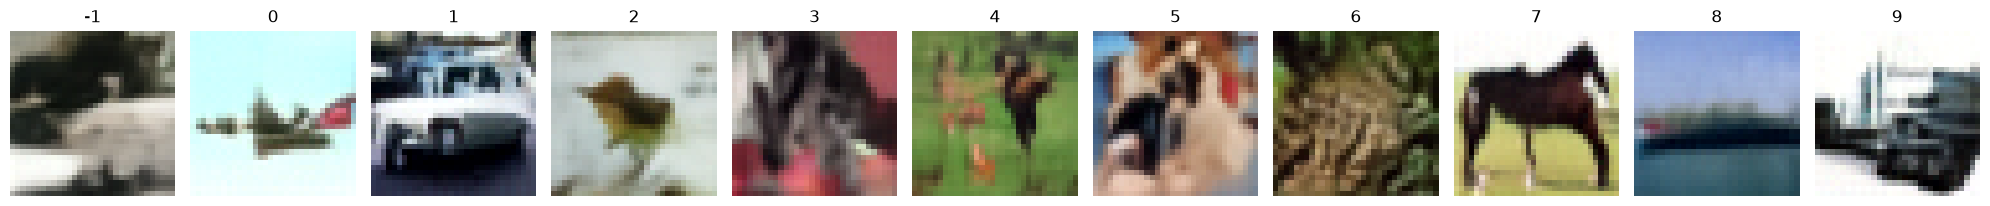

Epoch 67/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9512 - classifier_loss: 0.1412 - loss: 0.0293 - noise_loss: 0.0289 - val_classifier_accuracy: 0.8154 - val_classifier_loss: 0.7971 - val_image_loss: 0.0727 - val_loss: 0.0330 - val_noise_loss: 0.0312 - learning_rate: 2.4548e-04
Steps: 100/100


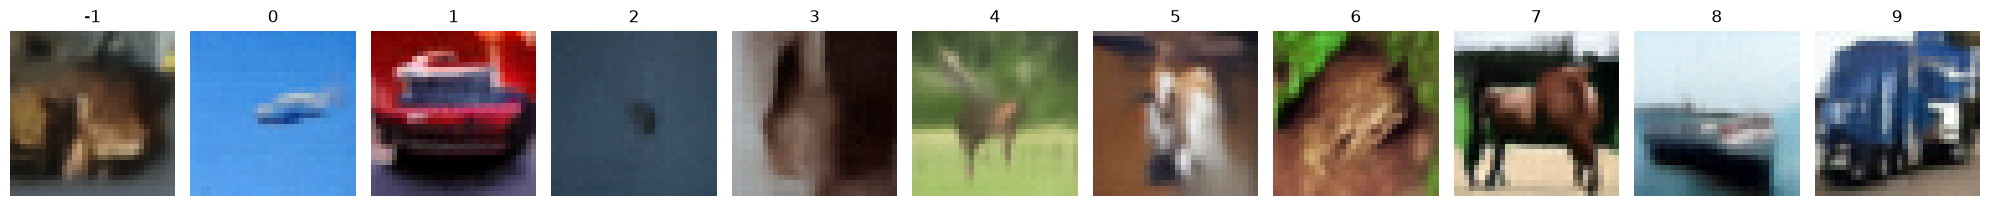

Epoch 68/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 37s 95ms/step - classifier_accuracy: 0.9548 - classifier_loss: 0.1293 - loss: 0.0291 - noise_loss: 0.0288 - val_classifier_accuracy: 0.8182 - val_classifier_loss: 0.8338 - val_image_loss: 0.0755 - val_loss: 0.0334 - val_noise_loss: 0.0316 - learning_rate: 2.3209e-04
Steps: 100/100


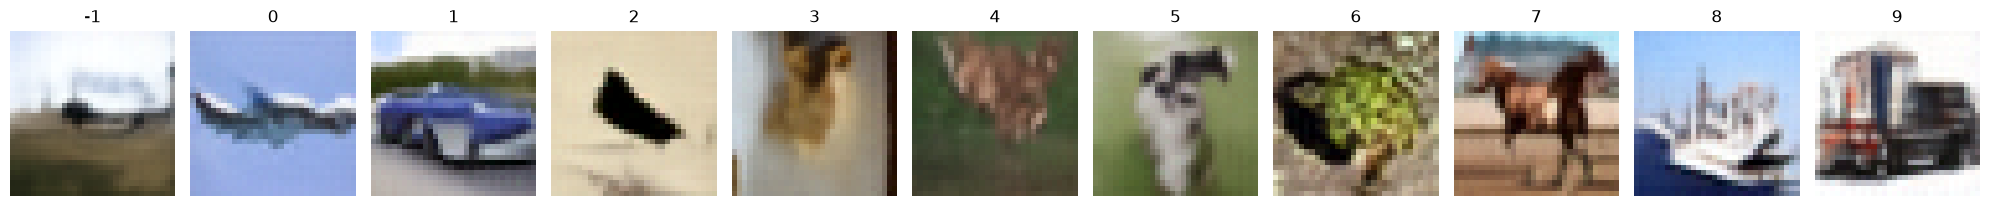

Epoch 69/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 38s 97ms/step - classifier_accuracy: 0.9570 - classifier_loss: 0.1245 - loss: 0.0293 - noise_loss: 0.0291 - val_classifier_accuracy: 0.8137 - val_classifier_loss: 0.8364 - val_image_loss: 0.0748 - val_loss: 0.0335 - val_noise_loss: 0.0317 - learning_rate: 2.1896e-04
Steps: 100/100


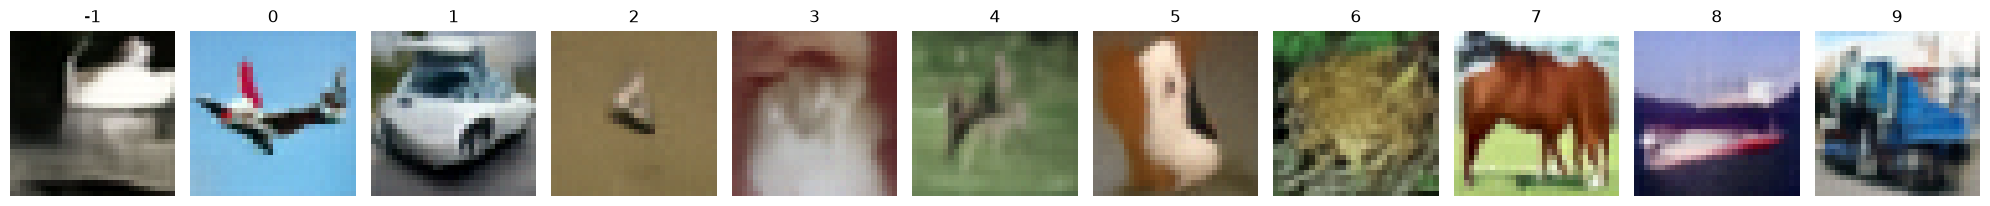

Epoch 70/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 38s 98ms/step - classifier_accuracy: 0.9578 - classifier_loss: 0.1213 - loss: 0.0294 - noise_loss: 0.0291 - val_classifier_accuracy: 0.8221 - val_classifier_loss: 0.8060 - val_image_loss: 0.0710 - val_loss: 0.0335 - val_noise_loss: 0.0317 - learning_rate: 2.0611e-04
Steps: 100/100


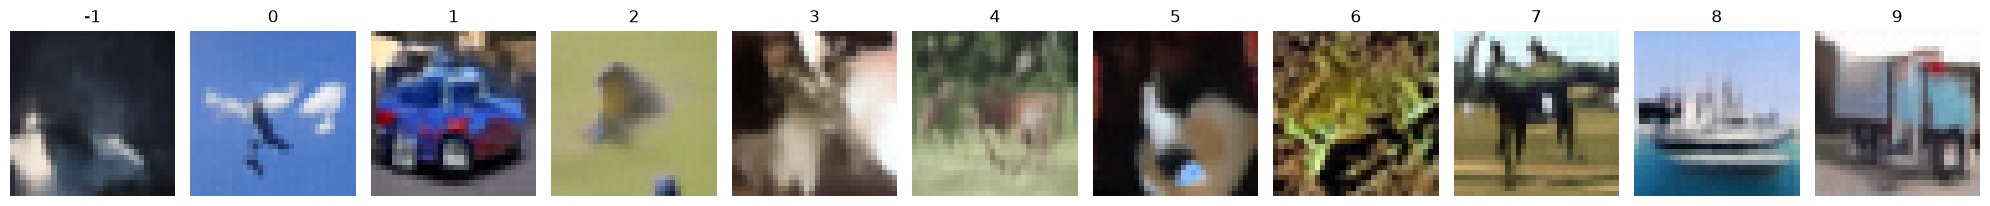

Epoch 71/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 38s 98ms/step - classifier_accuracy: 0.9604 - classifier_loss: 0.1148 - loss: 0.0293 - noise_loss: 0.0290 - val_classifier_accuracy: 0.8175 - val_classifier_loss: 0.8614 - val_image_loss: 0.0717 - val_loss: 0.0332 - val_noise_loss: 0.0313 - learning_rate: 1.9355e-04
Steps: 100/100


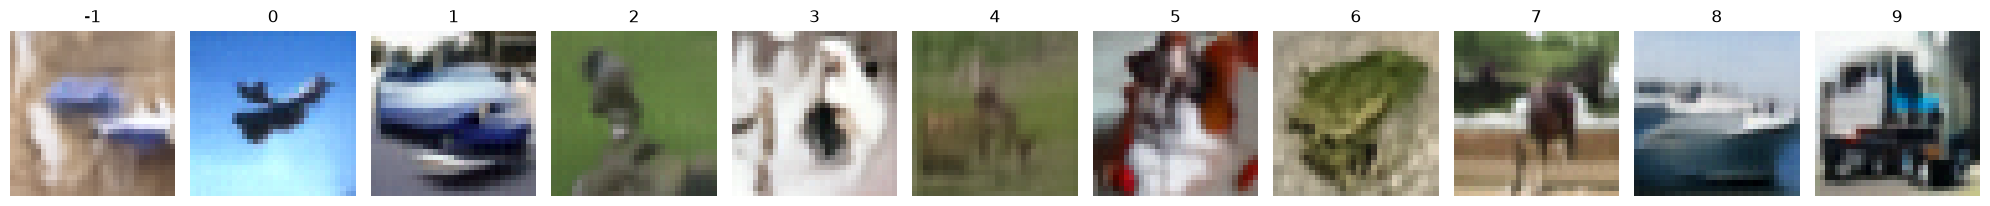

Epoch 72/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 38s 98ms/step - classifier_accuracy: 0.9620 - classifier_loss: 0.1096 - loss: 0.0294 - noise_loss: 0.0292 - val_classifier_accuracy: 0.8161 - val_classifier_loss: 0.8459 - val_image_loss: 0.0730 - val_loss: 0.0332 - val_noise_loss: 0.0314 - learning_rate: 1.8129e-04
Steps: 100/100


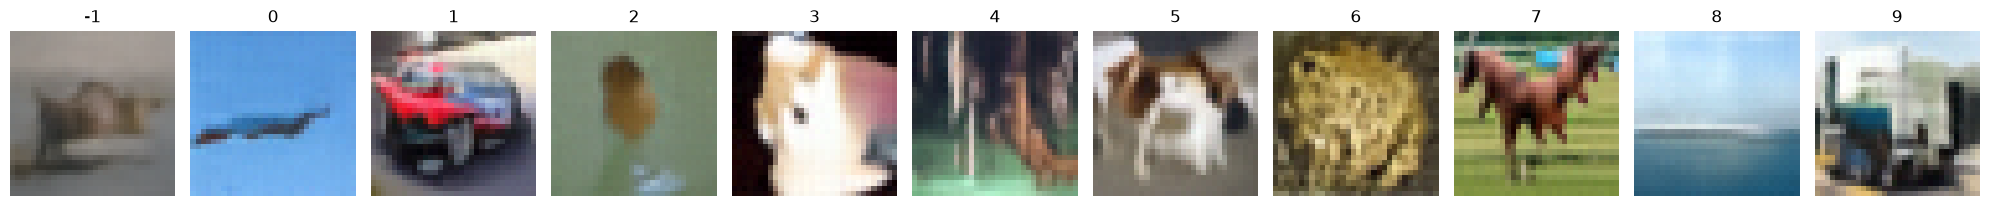

Epoch 73/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9649 - classifier_loss: 0.1019 - loss: 0.0293 - noise_loss: 0.0291 - val_classifier_accuracy: 0.8149 - val_classifier_loss: 0.8407 - val_image_loss: 0.0726 - val_loss: 0.0330 - val_noise_loss: 0.0312 - learning_rate: 1.6934e-04
Steps: 100/100


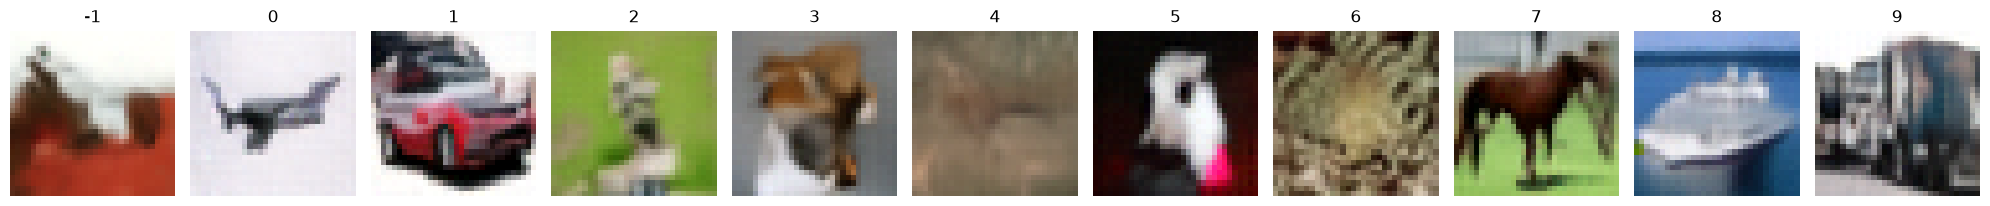

Epoch 74/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.9663 - classifier_loss: 0.0999 - loss: 0.0294 - noise_loss: 0.0292 - val_classifier_accuracy: 0.8169 - val_classifier_loss: 0.8849 - val_image_loss: 0.0736 - val_loss: 0.0326 - val_noise_loss: 0.0307 - learning_rate: 1.5773e-04
Steps: 100/100


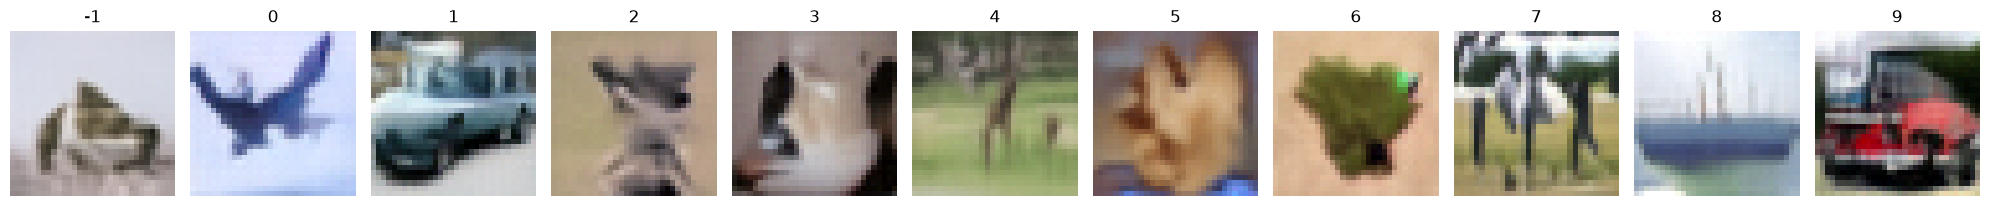

Epoch 75/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9679 - classifier_loss: 0.0937 - loss: 0.0292 - noise_loss: 0.0290 - val_classifier_accuracy: 0.8191 - val_classifier_loss: 0.8563 - val_image_loss: 0.0716 - val_loss: 0.0333 - val_noise_loss: 0.0314 - learning_rate: 1.4645e-04
Steps: 100/100


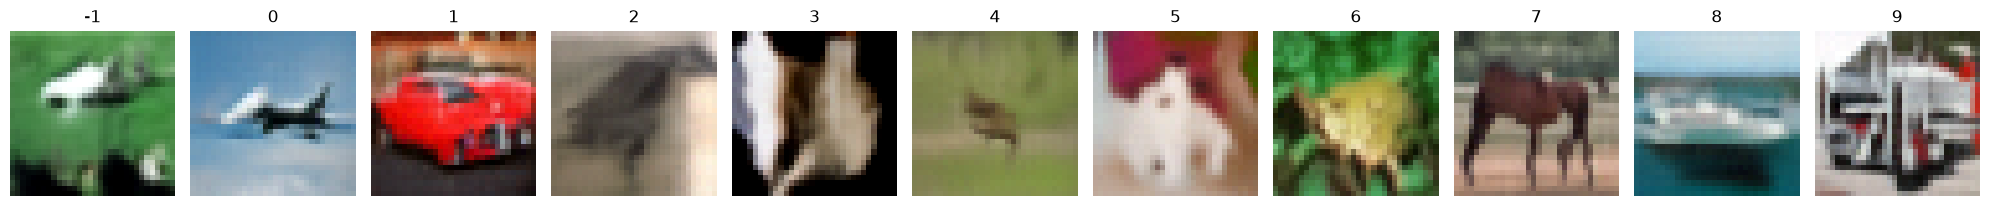

Epoch 76/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9686 - classifier_loss: 0.0890 - loss: 0.0292 - noise_loss: 0.0290 - val_classifier_accuracy: 0.8156 - val_classifier_loss: 0.9171 - val_image_loss: 0.0734 - val_loss: 0.0331 - val_noise_loss: 0.0311 - learning_rate: 1.3552e-04
Steps: 100/100


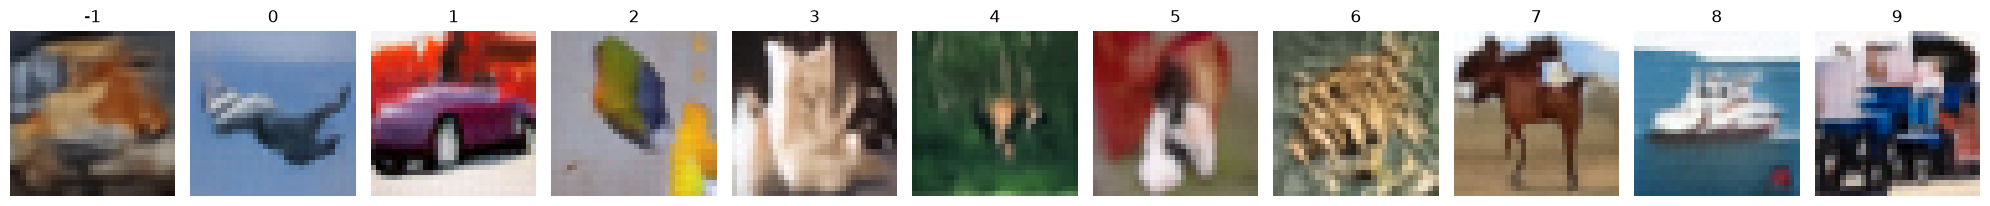

Epoch 77/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9699 - classifier_loss: 0.0877 - loss: 0.0296 - noise_loss: 0.0294 - val_classifier_accuracy: 0.8193 - val_classifier_loss: 0.8906 - val_image_loss: 0.0712 - val_loss: 0.0339 - val_noise_loss: 0.0320 - learning_rate: 1.2494e-04
Steps: 100/100


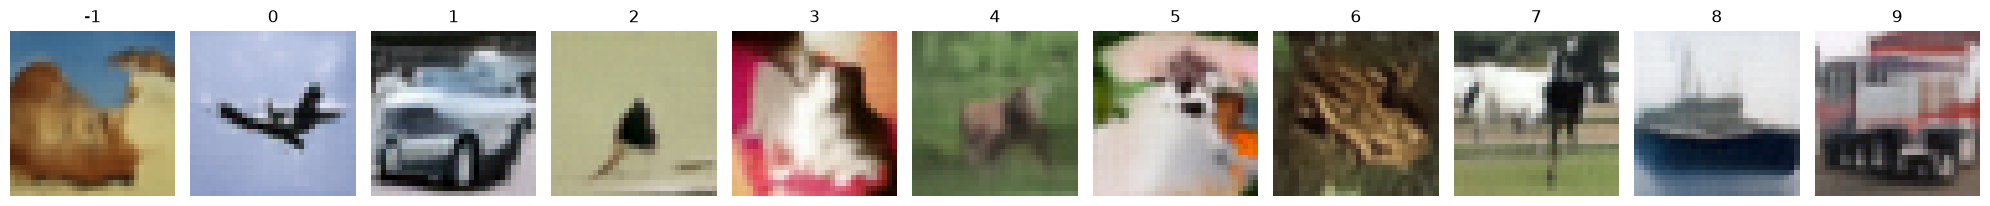

Epoch 78/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9722 - classifier_loss: 0.0825 - loss: 0.0291 - noise_loss: 0.0289 - val_classifier_accuracy: 0.8171 - val_classifier_loss: 0.9290 - val_image_loss: 0.0727 - val_loss: 0.0330 - val_noise_loss: 0.0310 - learning_rate: 1.1474e-04
Steps: 100/100


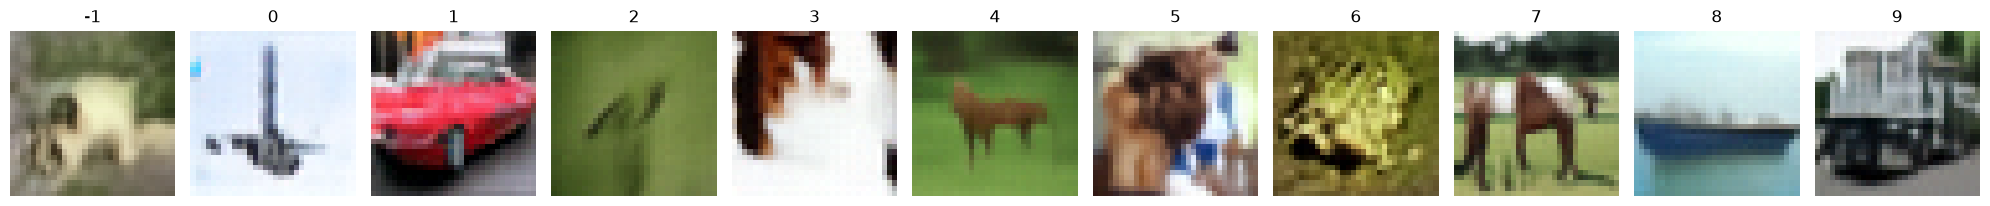

Epoch 79/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9739 - classifier_loss: 0.0771 - loss: 0.0291 - noise_loss: 0.0289 - val_classifier_accuracy: 0.8198 - val_classifier_loss: 0.8909 - val_image_loss: 0.0715 - val_loss: 0.0338 - val_noise_loss: 0.0319 - learning_rate: 1.0492e-04
Steps: 100/100


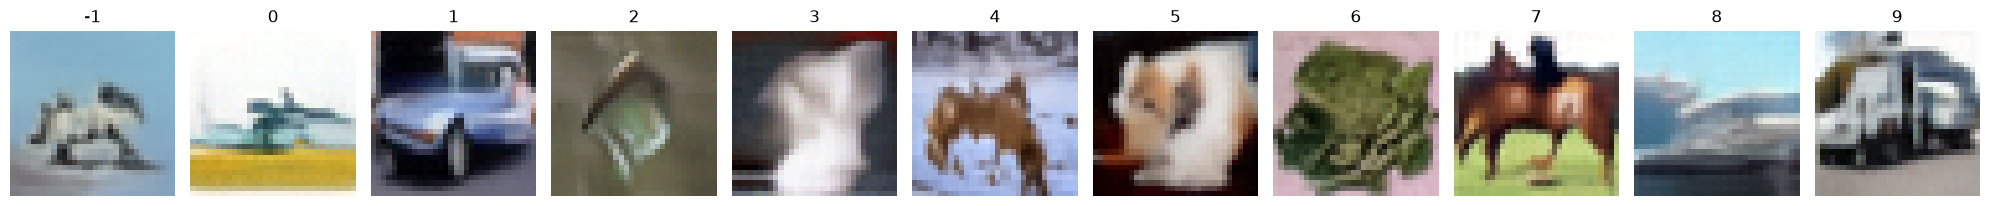

Epoch 80/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 102ms/step - classifier_accuracy: 0.9741 - classifier_loss: 0.0753 - loss: 0.0289 - noise_loss: 0.0287 - val_classifier_accuracy: 0.8184 - val_classifier_loss: 0.8847 - val_image_loss: 0.0727 - val_loss: 0.0326 - val_noise_loss: 0.0307 - learning_rate: 9.5491e-05
Steps: 100/100


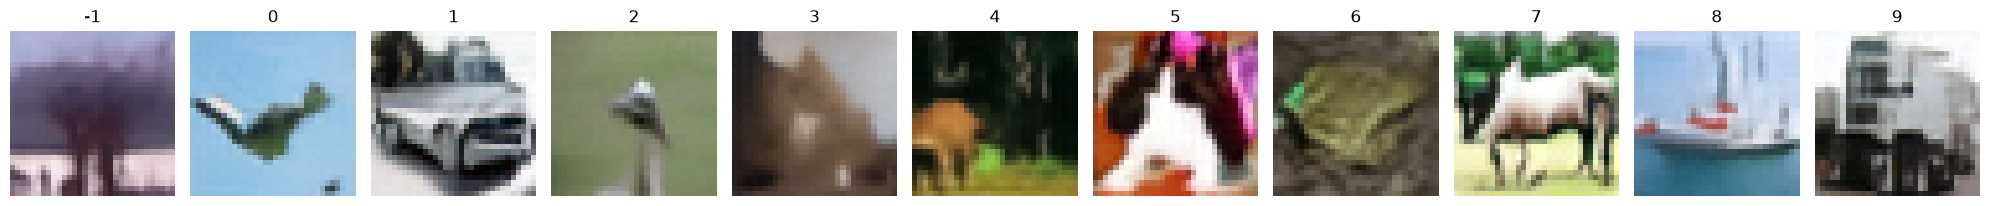

Epoch 81/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.9759 - classifier_loss: 0.0713 - loss: 0.0293 - noise_loss: 0.0292 - val_classifier_accuracy: 0.8179 - val_classifier_loss: 0.9234 - val_image_loss: 0.0726 - val_loss: 0.0329 - val_noise_loss: 0.0310 - learning_rate: 8.6460e-05
Steps: 100/100


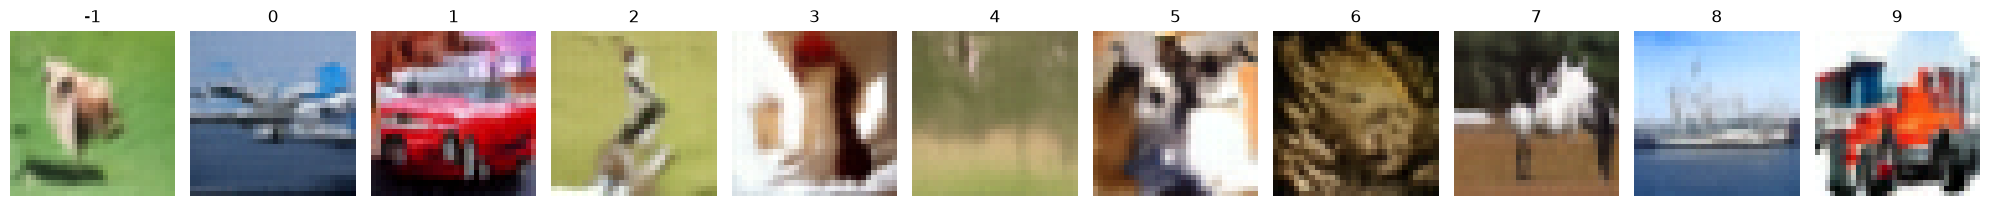

Epoch 82/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9754 - classifier_loss: 0.0723 - loss: 0.0290 - noise_loss: 0.0289 - val_classifier_accuracy: 0.8198 - val_classifier_loss: 0.9211 - val_image_loss: 0.0709 - val_loss: 0.0335 - val_noise_loss: 0.0315 - learning_rate: 7.7836e-05
Steps: 100/100


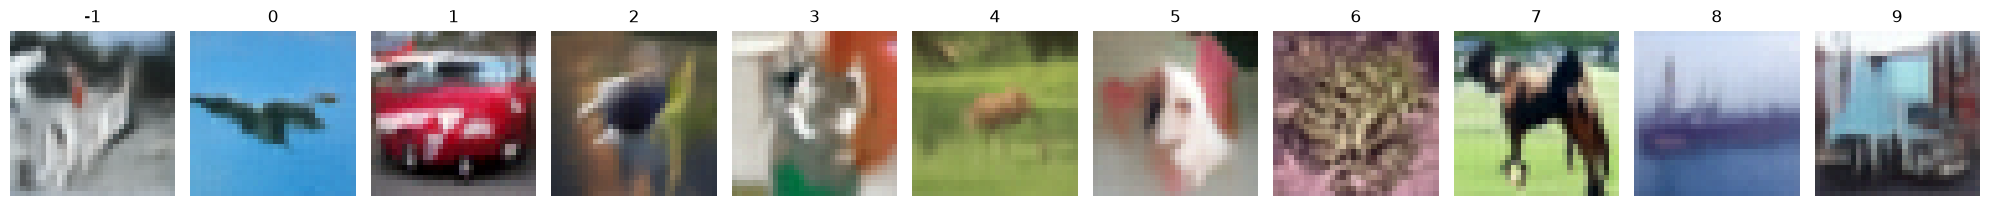

Epoch 83/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 39s 101ms/step - classifier_accuracy: 0.9771 - classifier_loss: 0.0657 - loss: 0.0290 - noise_loss: 0.0289 - val_classifier_accuracy: 0.8232 - val_classifier_loss: 0.9072 - val_image_loss: 0.0721 - val_loss: 0.0332 - val_noise_loss: 0.0313 - learning_rate: 6.9629e-05
Steps: 100/100


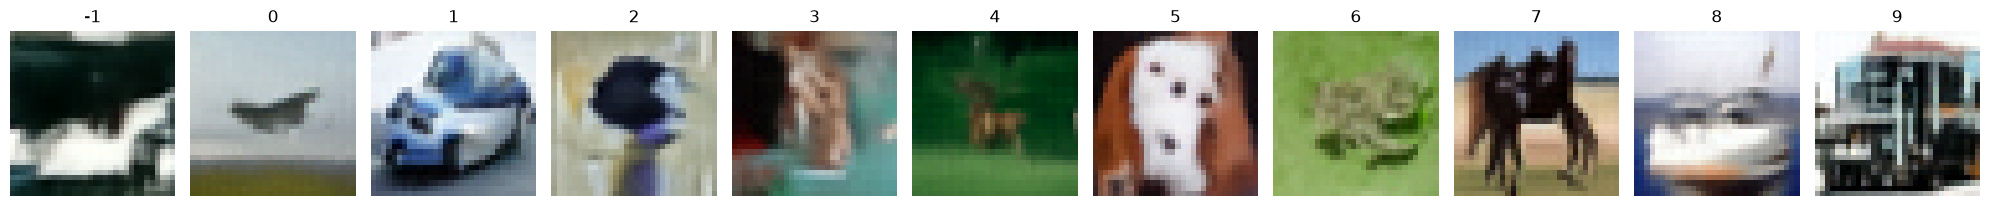

Epoch 84/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 102ms/step - classifier_accuracy: 0.9781 - classifier_loss: 0.0659 - loss: 0.0290 - noise_loss: 0.0288 - val_classifier_accuracy: 0.8213 - val_classifier_loss: 0.9210 - val_image_loss: 0.0718 - val_loss: 0.0335 - val_noise_loss: 0.0316 - learning_rate: 6.1847e-05
Steps: 100/100


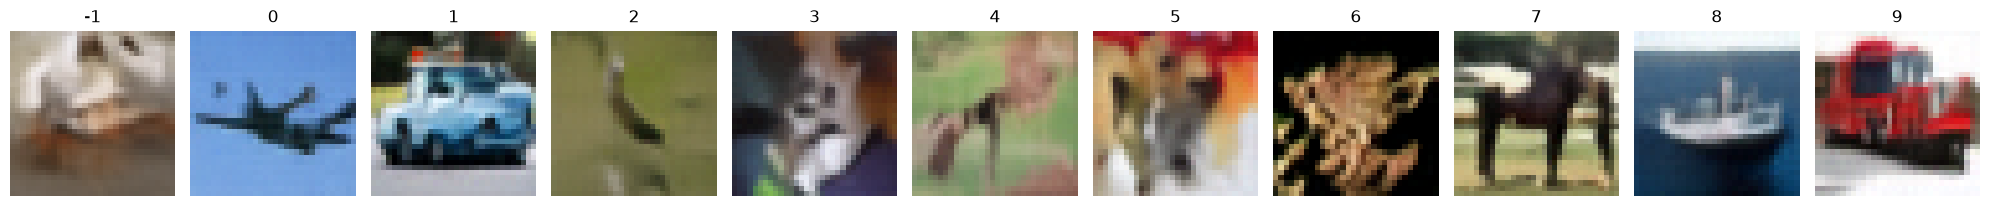

Epoch 85/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.9794 - classifier_loss: 0.0617 - loss: 0.0291 - noise_loss: 0.0289 - val_classifier_accuracy: 0.8230 - val_classifier_loss: 0.9512 - val_image_loss: 0.0706 - val_loss: 0.0330 - val_noise_loss: 0.0309 - learning_rate: 5.4497e-05
Steps: 100/100


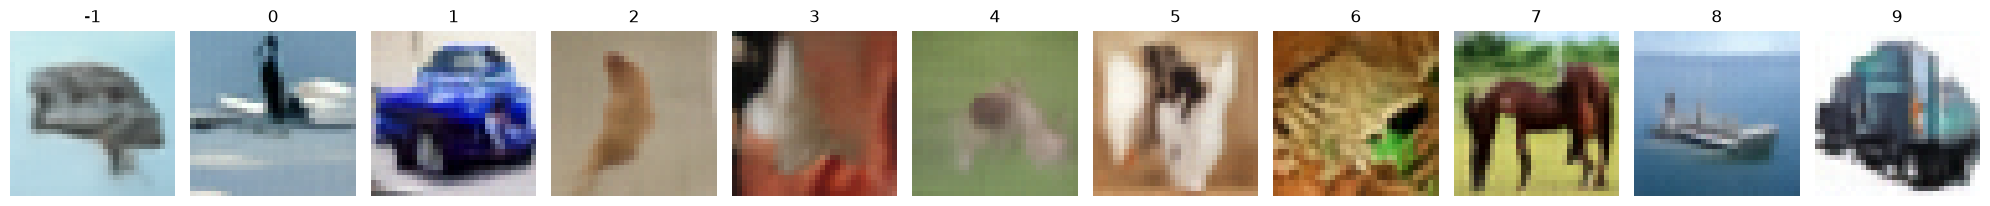

Epoch 86/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9789 - classifier_loss: 0.0613 - loss: 0.0288 - noise_loss: 0.0287 - val_classifier_accuracy: 0.8216 - val_classifier_loss: 0.9648 - val_image_loss: 0.0719 - val_loss: 0.0333 - val_noise_loss: 0.0312 - learning_rate: 4.7586e-05
Steps: 100/100


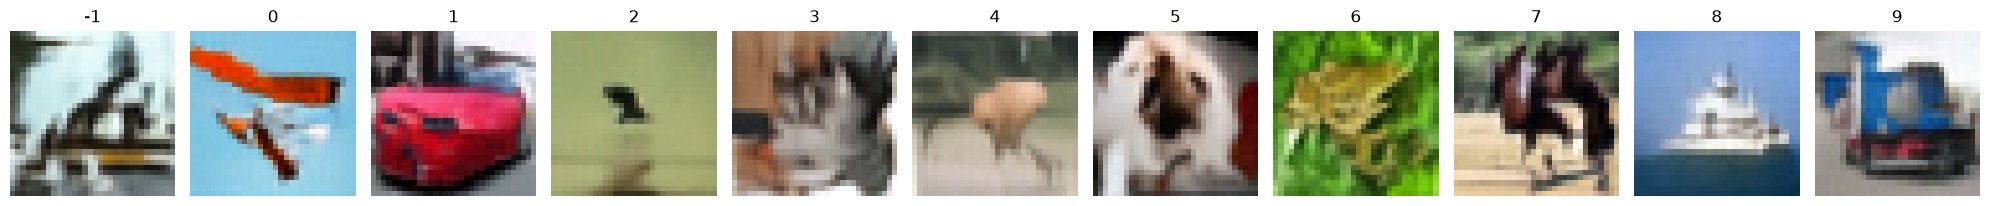

Epoch 87/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9816 - classifier_loss: 0.0551 - loss: 0.0288 - noise_loss: 0.0287 - val_classifier_accuracy: 0.8235 - val_classifier_loss: 0.9813 - val_image_loss: 0.0724 - val_loss: 0.0329 - val_noise_loss: 0.0308 - learning_rate: 4.1123e-05
Steps: 100/100


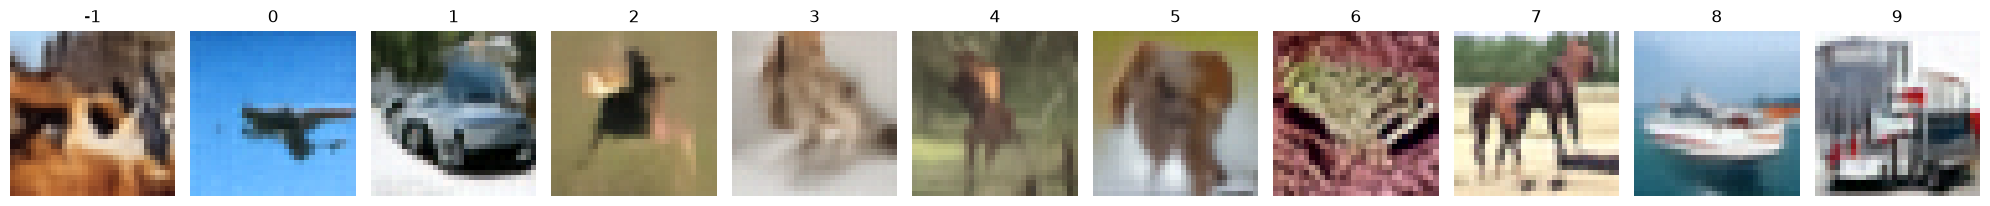

Epoch 88/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9818 - classifier_loss: 0.0550 - loss: 0.0288 - noise_loss: 0.0287 - val_classifier_accuracy: 0.8217 - val_classifier_loss: 0.9827 - val_image_loss: 0.0699 - val_loss: 0.0333 - val_noise_loss: 0.0312 - learning_rate: 3.5112e-05
Steps: 100/100


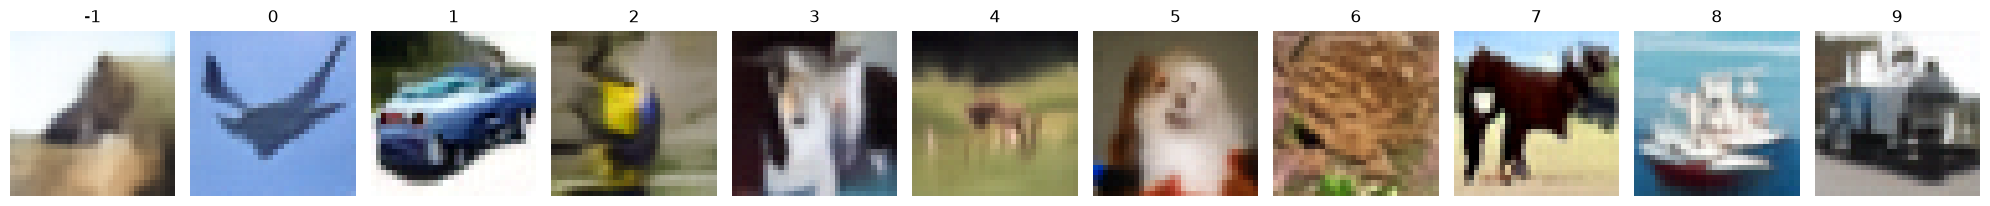

Epoch 89/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 101ms/step - classifier_accuracy: 0.9811 - classifier_loss: 0.0539 - loss: 0.0288 - noise_loss: 0.0286 - val_classifier_accuracy: 0.8226 - val_classifier_loss: 0.9997 - val_image_loss: 0.0728 - val_loss: 0.0339 - val_noise_loss: 0.0317 - learning_rate: 2.9560e-05
Steps: 100/100


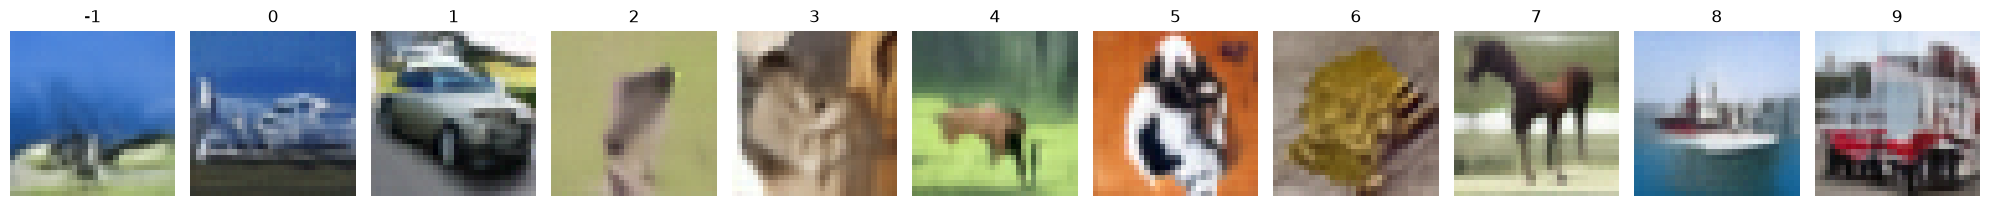

Epoch 90/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 104ms/step - classifier_accuracy: 0.9822 - classifier_loss: 0.0540 - loss: 0.0290 - noise_loss: 0.0289 - val_classifier_accuracy: 0.8201 - val_classifier_loss: 1.0124 - val_image_loss: 0.0717 - val_loss: 0.0327 - val_noise_loss: 0.0305 - learning_rate: 2.4472e-05
Steps: 100/100


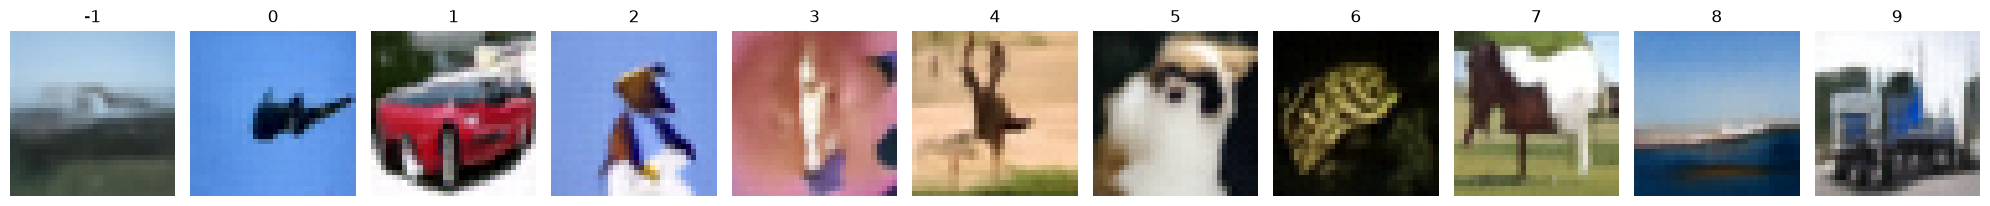

Epoch 91/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9833 - classifier_loss: 0.0500 - loss: 0.0289 - noise_loss: 0.0288 - val_classifier_accuracy: 0.8249 - val_classifier_loss: 1.0036 - val_image_loss: 0.0693 - val_loss: 0.0340 - val_noise_loss: 0.0318 - learning_rate: 1.9853e-05
Steps: 100/100


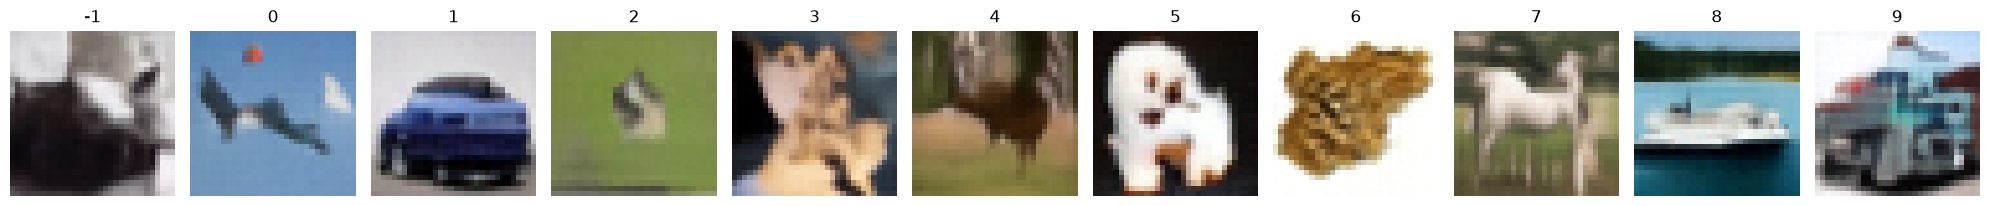

Epoch 92/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 104ms/step - classifier_accuracy: 0.9825 - classifier_loss: 0.0513 - loss: 0.0289 - noise_loss: 0.0288 - val_classifier_accuracy: 0.8254 - val_classifier_loss: 0.9946 - val_image_loss: 0.0714 - val_loss: 0.0342 - val_noise_loss: 0.0321 - learning_rate: 1.5708e-05
Steps: 100/100


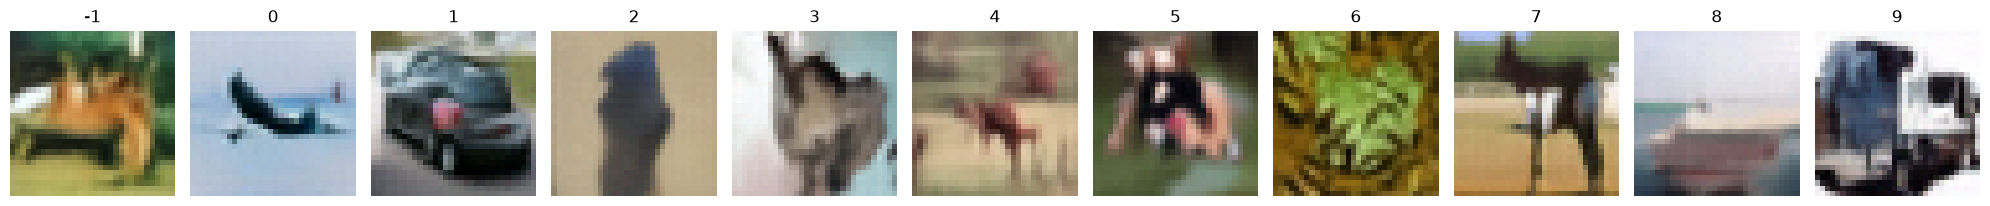

Epoch 93/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 104ms/step - classifier_accuracy: 0.9833 - classifier_loss: 0.0492 - loss: 0.0290 - noise_loss: 0.0289 - val_classifier_accuracy: 0.8245 - val_classifier_loss: 0.9966 - val_image_loss: 0.0707 - val_loss: 0.0329 - val_noise_loss: 0.0307 - learning_rate: 1.2042e-05
Steps: 100/100


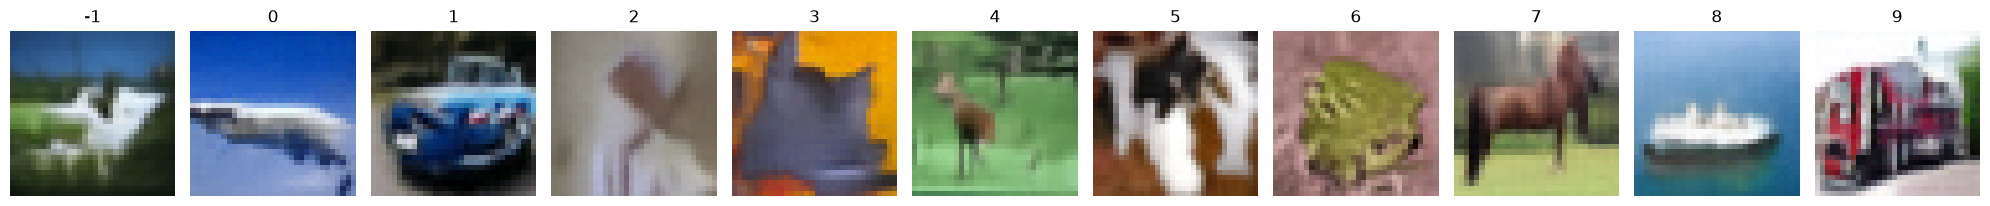

Epoch 94/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9834 - classifier_loss: 0.0502 - loss: 0.0291 - noise_loss: 0.0290 - val_classifier_accuracy: 0.8253 - val_classifier_loss: 0.9934 - val_image_loss: 0.0715 - val_loss: 0.0336 - val_noise_loss: 0.0315 - learning_rate: 8.8564e-06
Steps: 100/100


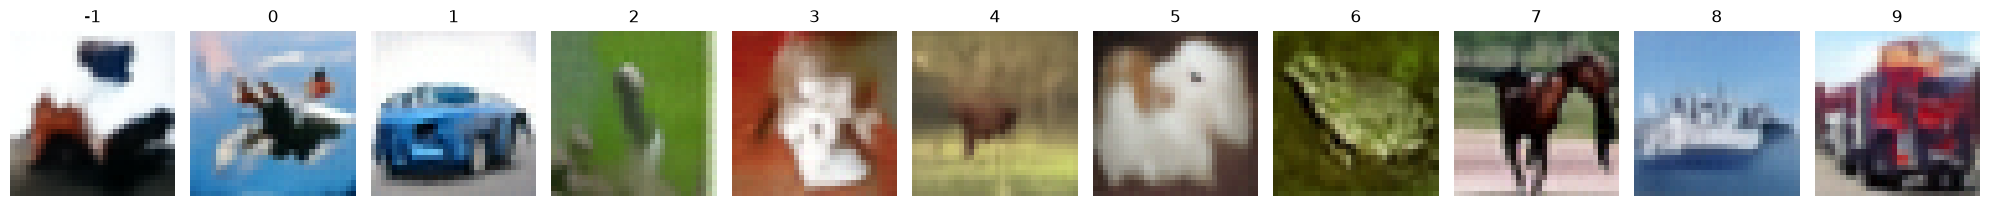

Epoch 95/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.9830 - classifier_loss: 0.0491 - loss: 0.0288 - noise_loss: 0.0287 - val_classifier_accuracy: 0.8238 - val_classifier_loss: 0.9924 - val_image_loss: 0.0728 - val_loss: 0.0329 - val_noise_loss: 0.0307 - learning_rate: 6.1558e-06
Steps: 100/100


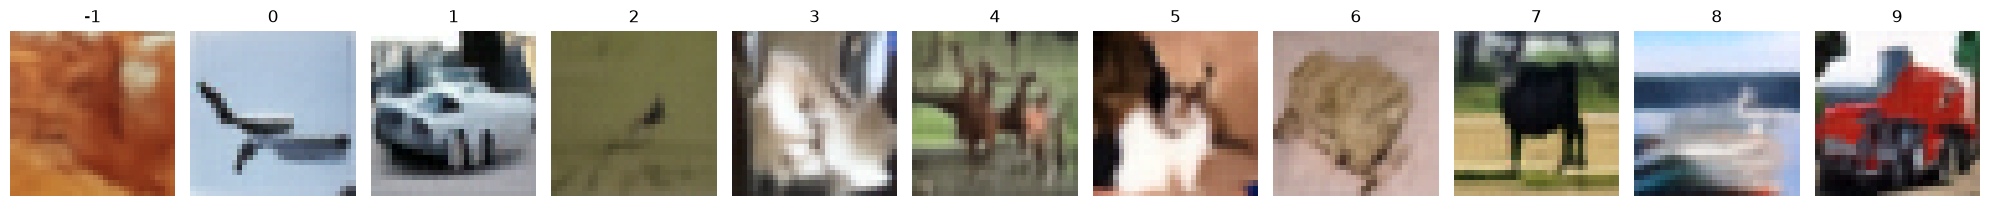

Epoch 96/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.9842 - classifier_loss: 0.0484 - loss: 0.0290 - noise_loss: 0.0289 - val_classifier_accuracy: 0.8243 - val_classifier_loss: 0.9918 - val_image_loss: 0.0719 - val_loss: 0.0327 - val_noise_loss: 0.0306 - learning_rate: 3.9426e-06
Steps: 100/100


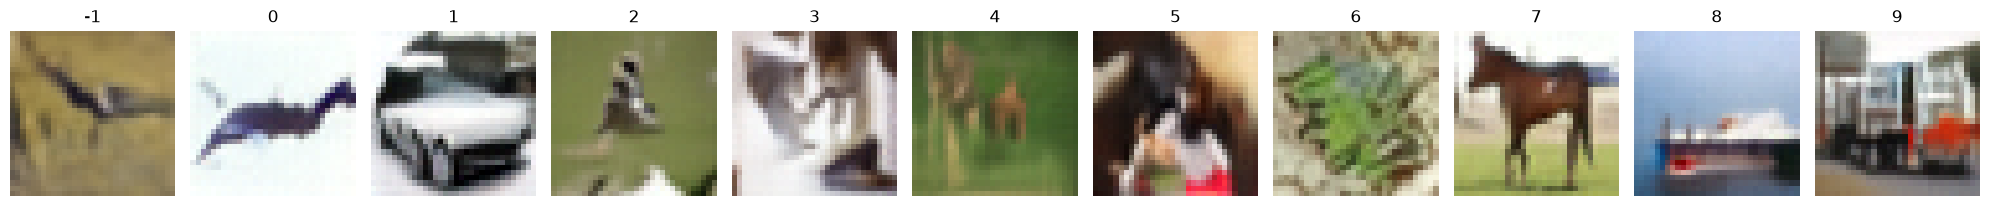

Epoch 97/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - classifier_accuracy: 0.9843 - classifier_loss: 0.0476 - loss: 0.0285 - noise_loss: 0.0284 - val_classifier_accuracy: 0.8235 - val_classifier_loss: 0.9985 - val_image_loss: 0.0709 - val_loss: 0.0336 - val_noise_loss: 0.0314 - learning_rate: 2.2190e-06
Steps: 100/100


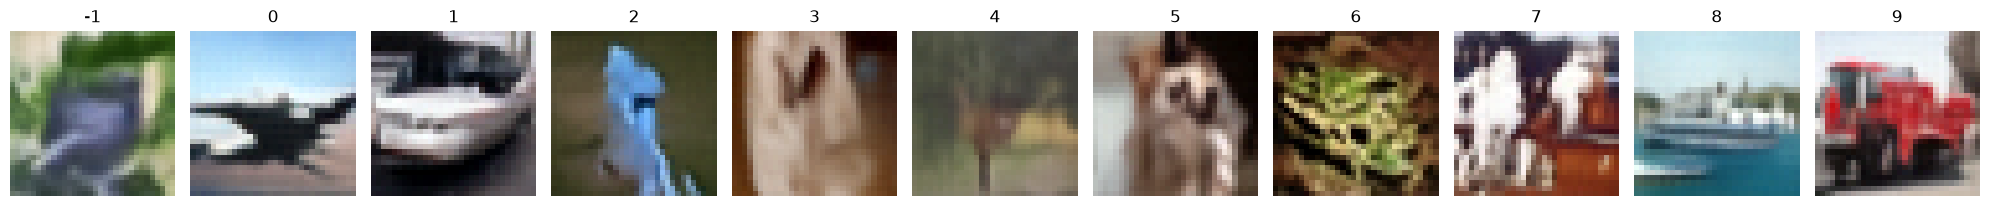

Epoch 98/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 104ms/step - classifier_accuracy: 0.9844 - classifier_loss: 0.0466 - loss: 0.0286 - noise_loss: 0.0285 - val_classifier_accuracy: 0.8238 - val_classifier_loss: 0.9995 - val_image_loss: 0.0720 - val_loss: 0.0330 - val_noise_loss: 0.0309 - learning_rate: 9.8664e-07
Steps: 100/100


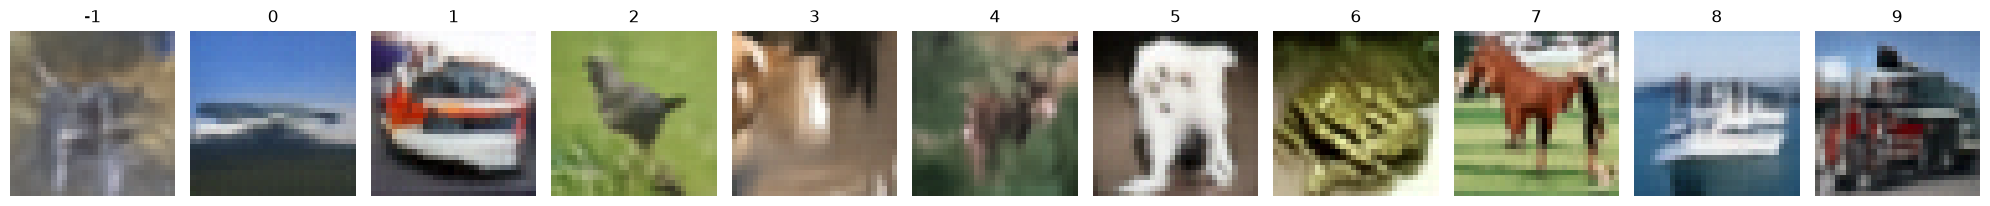

Epoch 99/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - classifier_accuracy: 0.9843 - classifier_loss: 0.0473 - loss: 0.0288 - noise_loss: 0.0287 - val_classifier_accuracy: 0.8236 - val_classifier_loss: 0.9997 - val_image_loss: 0.0725 - val_loss: 0.0329 - val_noise_loss: 0.0308 - learning_rate: 2.4673e-07
Steps: 100/100


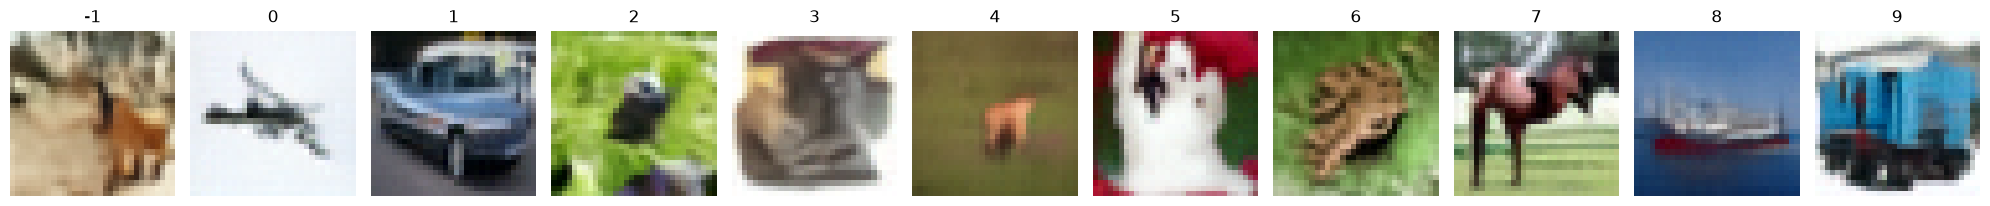

Epoch 100/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 40s 102ms/step - classifier_accuracy: 0.9847 - classifier_loss: 0.0455 - loss: 0.0290 - noise_loss: 0.0289 - val_classifier_accuracy: 0.8237 - val_classifier_loss: 0.9997 - val_image_loss: 0.0701 - val_loss: 0.0331 - val_noise_loss: 0.0310 - learning_rate: 0.0000e+00
Steps: 100/100


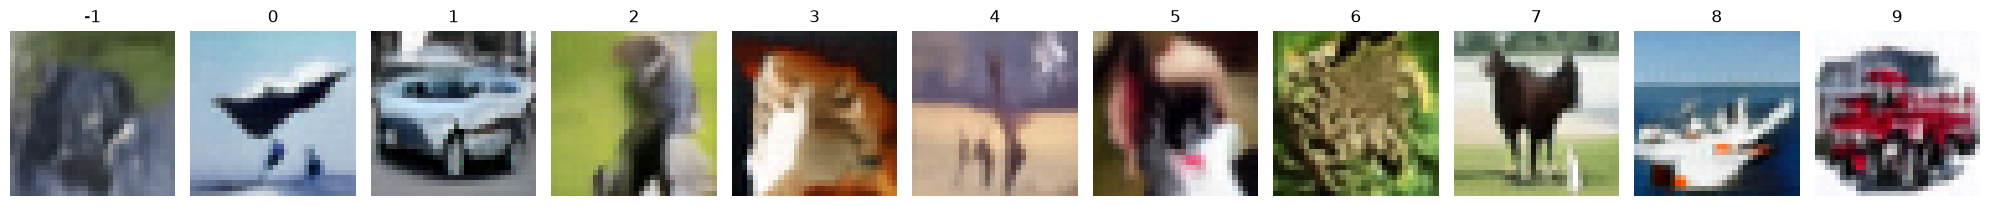

In [8]:
history = model.fit(
    trainset, 
    epochs=epochs, 
    validation_data=valset, 
    callbacks=callbacks_list
).history

## Save weights


In [ ]:
model.save_weights("./files/models/CIFAR10 DiT CLF/model.weights.h5")

## Evaluate EMA and raw networks


In [10]:
model.evaluate(valset, network_name="ema")

79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - classifier_accuracy: 0.8237 - classifier_loss: 0.9997 - image_loss: 0.0705 - loss: 0.0330 - noise_loss: 0.0309


[<tf.Tensor: shape=(), dtype=float32, numpy=0.033026594668626785>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.030877280980348587>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.07050804048776627>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.9996763467788696>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.8237000107765198>]

In [11]:
model.evaluate(valset, network_name="raw")

79/79 ━━━━━━━━━━━━━━━━━━━━ 37s 212ms/step - classifier_accuracy: 0.8237 - classifier_loss: 0.9997 - image_loss: 0.0709 - loss: 0.0330 - noise_loss: 0.0309


[<tf.Tensor: shape=(), dtype=float32, numpy=0.03302135318517685>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.030872054398059845>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.07087711244821548>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.9996763467788696>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.8237000107765198>]

## Ensemble evaluation


In [12]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=256, 
    t_range_drop_rate=0.75
)

Step (79/79) --- Ensemble Accuracy: 0.8304


2026-10-12 22:38:46.704734: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


0.8303999900817871

In [13]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=256, 
    t_range_drop_rate=0.99
)

Step (79/79) --- Ensemble Accuracy: 0.8272


2026-10-12 22:39:42.115398: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


0.8271999955177307

In [14]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=128, 
    t_range_drop_rate=0.75
)

Step (79/79) --- Ensemble Accuracy: 0.8301


0.8300999999046326

In [15]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=128, 
    t_range_drop_rate=0.99
)

Step (79/79) --- Ensemble Accuracy: 0.8259


2026-10-12 22:50:03.581397: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


0.8259000182151794

In [16]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=64, 
    t_range_drop_rate=0.75
)

Step (79/79) --- Ensemble Accuracy: 0.8300


0.8299999833106995

In [17]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=64, 
    t_range_drop_rate=0.99
)

Step (79/79) --- Ensemble Accuracy: 0.8237


0.8237000107765198

In [18]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=32, 
    t_range_drop_rate=0.75
)

Step (79/79) --- Ensemble Accuracy: 0.8318


0.8317999839782715

In [19]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=32, 
    t_range_drop_rate=0.99
)

Step (79/79) --- Ensemble Accuracy: 0.8237


2026-10-12 22:58:02.071636: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


0.8237000107765198

In [20]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=16, 
    t_range_drop_rate=0.75
)

Step (79/79) --- Ensemble Accuracy: 0.8300


0.8299999833106995

In [21]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=16, 
    t_range_drop_rate=0.99
)

Step (79/79) --- Ensemble Accuracy: 0.8237


0.8237000107765198

In [ ]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=8
)

Step (79/79) --- Ensemble Accuracy: 0.8323


0.8323000073432922

In [ ]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=4
)

Step (79/79) --- Ensemble Accuracy: 0.8333


0.833299994468689

## Class-conditional samples


Steps: 100/100


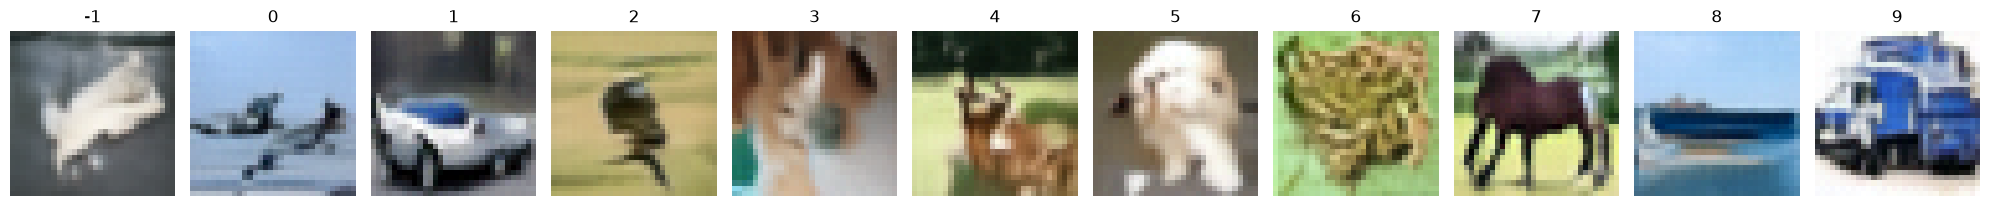

In [ ]:
from common.utils import plot_images


imgs = model.sample(add_null_label=True, scale=3., eta=0., steps=100, verbose=True)
plot_images(imgs, has_null_label=True)

Steps: 100/100


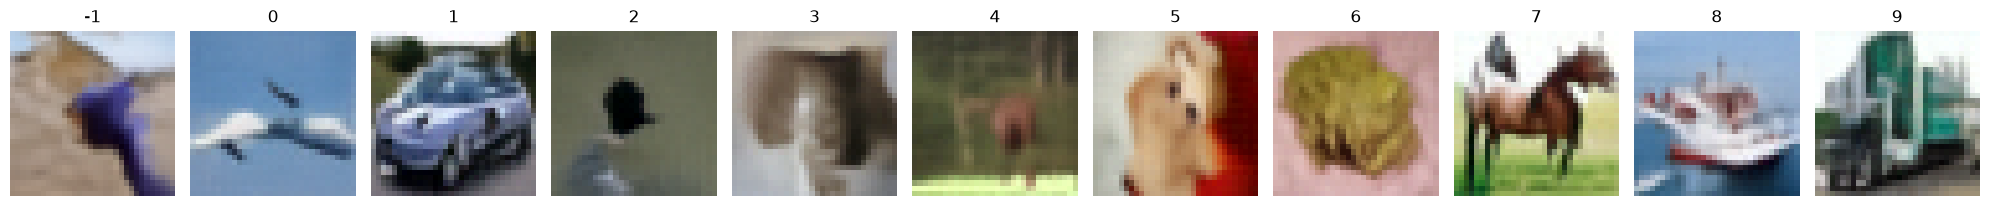

In [ ]:
imgs = model.sample(add_null_label=True, scale=3., steps=100, verbose=True)
plot_images(imgs, has_null_label=True)

Steps: 100/100


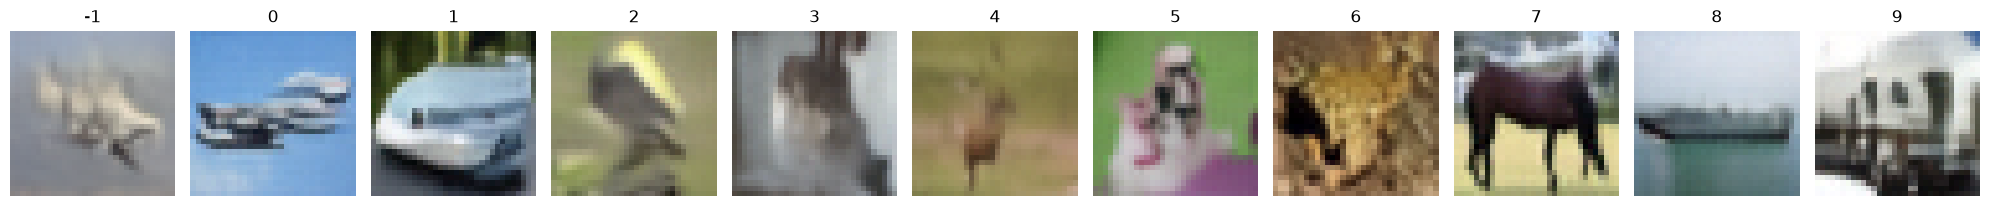

In [ ]:
imgs = model.sample(add_null_label=True, scale=3., verbose=True)
plot_images(imgs, has_null_label=True)

In [ ]:
imgs = model.sample(add_null_label=True, scale=3., verbose=True)
plot_images(imgs, has_null_label=True)

Steps: 74/100

## Training history


In [ ]:
from common.utils import plot_history


plot_history(history, show_all_x_ticks=False)

In [ ]:
plot_history(history, show_all_x_ticks=False, range_=(9, None))